find boundary and 2mins calibration

In [7]:
import pickle
import numpy as np

file_path = DATA_DIR / "S2" / "S2.pkl"

with file_path.open("rb") as f:
    data = pickle.load(f, encoding="latin1")

print("column：", list(data.keys()))
print("S：", data["subject"])
print("signal：", list(data["signal"].keys()))
print("wrist signal：", list(data["signal"]["wrist"].keys()))

column： ['signal', 'label', 'subject']
S： S2
signal： ['chest', 'wrist']
wrist signal： ['ACC', 'BVP', 'EDA', 'TEMP']


In [5]:
wrist = data["signal"]["wrist"]

BVP = np.asarray(wrist["BVP"]).reshape(-1)
EDA = np.asarray(wrist["EDA"]).reshape(-1)
TEMP = np.asarray(wrist["TEMP"]).reshape(-1)
ACC = np.asarray(wrist["ACC"])

labels = np.asarray(data["label"]).reshape(-1)

print("BVP shape：", BVP.shape)
print("EDA shape：", EDA.shape)
print("TEMP shape：", TEMP.shape)
print("ACC shape：", ACC.shape)
print("Labels shape：", labels.shape)

BVP shape： (389056,)
EDA shape： (24316,)
TEMP shape： (24316,)
ACC shape： (194528, 3)
Labels shape： (4255300,)


In [8]:
signals = {
    "BVP": (BVP, 64),
    "EDA": (EDA, 4),
    "TEMP": (TEMP, 4),
    "ACC": (ACC, 32),
}

for name, (values, fs) in signals.items():
    duration_min = len(values) / fs / 60
    invalid_count = np.count_nonzero(~np.isfinite(values))

    print(
        f"{name}: "
        f"recording length = {duration_min:.2f} min，"
        f"NaN/Inf number = {invalid_count}"
    )

print(f"Labels: recording length = {len(labels) / 700 / 60:.2f} min")

BVP: recording length = 101.32 min，NaN/Inf number = 0
EDA: recording length = 101.32 min，NaN/Inf number = 0
TEMP: recording length = 101.32 min，NaN/Inf number = 0
ACC: recording length = 101.32 min，NaN/Inf number = 0
Labels: recording length = 101.32 min


In [9]:
# find boundaries between different expertimental conditions so when doing the feature extracting we wont cut outside
# 4,255,300 labels in total，700/s

import numpy as np
import pandas as pd

LABEL_FS = 700

LABEL_NAMES = {
    0: "Transient / undefined",
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation",
    5: "Ignore",
    6: "Ignore",
    7: "Ignore",
}

# Find boundaries between consecutive experimental conditions.
change_points = np.flatnonzero(labels[1:] != labels[:-1]) + 1
boundaries = np.r_[0, change_points, len(labels)]

rows = []

for start_idx, end_idx in zip(boundaries[:-1], boundaries[1:]):
    label_code = int(labels[start_idx])

    rows.append({
        "label": label_code,
        "condition": LABEL_NAMES.get(label_code, "Unknown"),
        "start_s": start_idx / LABEL_FS,
        "end_s": end_idx / LABEL_FS,
        "duration_s": (end_idx - start_idx) / LABEL_FS,
    })

segments_df = pd.DataFrame(rows)

segments_df["start_min"] = segments_df["start_s"] / 60
segments_df["end_min"] = segments_df["end_s"] / 60
segments_df["duration_min"] = segments_df["duration_s"] / 60

display(
    segments_df[
        ["label", "condition", "start_min", "end_min", "duration_min"]
    ].round(3)
)

,label,condition,start_min,end_min,duration_min
0,0,Transient / undefined,0.000,5.109,5.109
1,1,Baseline,5.109,24.176,19.067
2,0,Transient / undefined,24.176,37.892,13.717
3,2,Stress,37.892,48.142,10.250
4,0,Transient / undefined,48.142,52.676,4.533
5,6,Ignore,52.676,53.759,1.083
6,0,Transient / undefined,53.759,68.292,14.533
7,4,Meditation,68.292,74.809,6.517
8,0,Transient / undefined,74.809,79.392,4.583
9,3,Amusement,79.392,85.426,6.033


In [10]:
## first two mins as baseline for individual



# Select the first continuous baseline interval.
baseline_segments = segments_df.loc[
    segments_df["label"] == 1
].copy()

if baseline_segments.empty:
    raise ValueError("No baseline interval was found.")

first_baseline = baseline_segments.iloc[0]

CALIBRATION_SECONDS = 120

calibration_start_s = float(first_baseline["start_s"])
calibration_end_s = calibration_start_s + CALIBRATION_SECONDS

if calibration_end_s > float(first_baseline["end_s"]):
    raise ValueError(
        "The first baseline interval is shorter than two minutes."
    )

print(
    f"Initial baseline: "
    f"{first_baseline['start_s'] / 60:.3f} to "
    f"{first_baseline['end_s'] / 60:.3f} minutes"
)

print(
    f"Calibration interval: "
    f"{calibration_start_s / 60:.3f} to "
    f"{calibration_end_s / 60:.3f} minutes"
)

print("Calibration duration: 120 seconds")

Initial baseline: 5.109 to 24.176 minutes
Calibration interval: 5.109 to 7.109 minutes
Calibration duration: 120 seconds


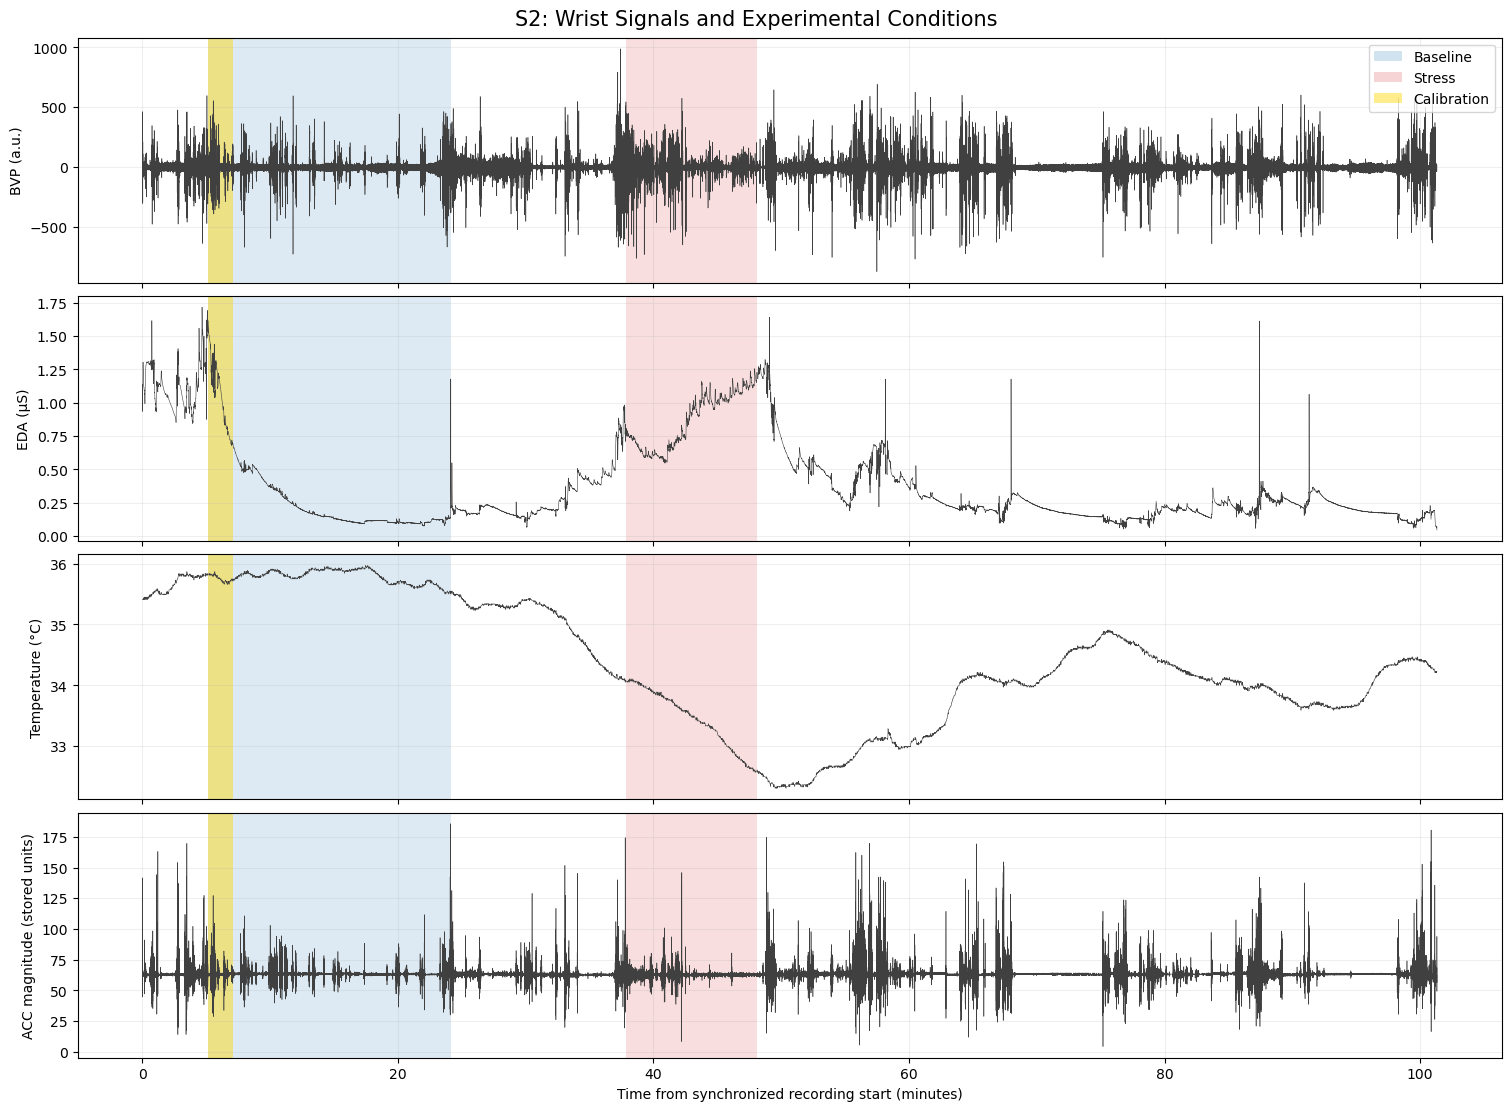

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

subject_id = str(data["subject"])

# Display acceleration magnitude in the stored units.
# Unit conversion will be checked before feature extraction.
acc_magnitude = np.linalg.norm(ACC.astype(float), axis=1)

plot_specs = [
    ("BVP", BVP, 64, "BVP (a.u.)"),
    ("EDA", EDA, 4, "EDA (µS)"),
    ("TEMP", TEMP, 4, "Temperature (°C)"),
    ("ACC", acc_magnitude, 32, "ACC magnitude (stored units)"),
]

condition_colors = {
    1: "tab:blue",
    2: "tab:red",
}

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 11),
    sharex=True,
    constrained_layout=True,
)

for ax, (name, values, fs, ylabel) in zip(axes, plot_specs):
    time_min = np.arange(len(values)) / fs / 60

    ax.plot(
        time_min,
        values,
        color="0.25",
        linewidth=0.4,
        rasterized=True,
    )

    # Shade baseline and stress intervals.
    for segment in segments_df.itertuples(index=False):
        if segment.label in condition_colors:
            ax.axvspan(
                segment.start_s / 60,
                segment.end_s / 60,
                color=condition_colors[segment.label],
                alpha=0.15,
                linewidth=0,
            )

    # Highlight the initial resting calibration interval.
    ax.axvspan(
        calibration_start_s / 60,
        calibration_end_s / 60,
        color="gold",
        alpha=0.45,
        linewidth=0,
    )

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

legend_handles = [
    Patch(facecolor="tab:blue", alpha=0.2, label="Baseline"),
    Patch(facecolor="tab:red", alpha=0.2, label="Stress"),
    Patch(facecolor="gold", alpha=0.45, label="Calibration"),
]

axes[0].legend(handles=legend_handles, loc="upper right")
axes[-1].set_xlabel("Time from synchronized recording start (minutes)")

fig.suptitle(
    f"{subject_id}: Wrist Signals and Experimental Conditions",
    fontsize=15,
)

plt.show()

baseline: 20mins, stress:10 mins. Windowing: 60s. first 2mins baseline not count into the windowing. last min less then 1 mins so also not count.

In [12]:
WINDOW_SECONDS = 60
LABEL_FS = 700
FS = {"BVP": 64, "EDA": 4, "TEMP": 4, "ACC": 32}

signal_arrays = {
    "BVP": BVP,
    "EDA": EDA,
    "TEMP": TEMP,
    "ACC": ACC,
}

subject_id = str(data["subject"])

# Identify continuous condition intervals using original label indices.
changes = np.flatnonzero(labels[1:] != labels[:-1]) + 1
edges = np.r_[0, changes, len(labels)]

baseline_starts = [
    int(start)
    for start, end in zip(edges[:-1], edges[1:])
    if int(labels[start]) == 1
]

if not baseline_starts:
    raise ValueError("No baseline interval was found.")

initial_baseline_start = baseline_starts[0]
window_label_count = WINDOW_SECONDS * LABEL_FS

window_rows = []
window_signals = {}
interval_rows = []

for segment_id, (segment_start, segment_end) in enumerate(
    zip(edges[:-1], edges[1:])
):
    segment_start = int(segment_start)
    segment_end = int(segment_end)
    label_code = int(labels[segment_start])

    if label_code not in (1, 2):
        continue

    condition = "Baseline" if label_code == 1 else "Stress"
    n_windows = (segment_end - segment_start) // window_label_count

    interval_rows.append({
        "condition": condition,
        "duration_s": (segment_end - segment_start) / LABEL_FS,
        "complete_windows": n_windows,
        "unused_tail_s": (
            segment_end - segment_start
            - n_windows * window_label_count
        ) / LABEL_FS,
    })

    for window_number in range(n_windows):
        start_idx = segment_start + window_number * window_label_count
        end_idx = start_idx + window_label_count

        # Verify that every label in this window has the same condition.
        if not np.all(labels[start_idx:end_idx] == label_code):
            raise ValueError("A window crosses a condition boundary.")

        window_id = (
            f"{subject_id}_seg{segment_id:02d}_"
            f"win{window_number + 1:02d}"
        )

        chunks = {}

        for name, values in signal_arrays.items():
            fs = FS[name]

            # Select samples whose timestamps lie in [start, end).
            # Integer ceiling division avoids floating-point rounding.
            signal_start = (start_idx * fs + LABEL_FS - 1) // LABEL_FS
            signal_end = (end_idx * fs + LABEL_FS - 1) // LABEL_FS

            if signal_end > len(values):
                raise ValueError(
                    f"{window_id}: insufficient {name} coverage."
                )

            chunk = values[signal_start:signal_end]

            if len(chunk) != WINDOW_SECONDS * fs:
                raise ValueError(
                    f"{window_id}: unexpected {name} sample count."
                )

            chunks[name] = chunk

        is_initial_baseline = (
            label_code == 1
            and segment_start == initial_baseline_start
        )

        calibration_2min = (
            is_initial_baseline and window_number < 2
        )
        calibration_5min = (
            is_initial_baseline and window_number < 5
        )

        window_rows.append({
            "subject_id": subject_id,
            "window_id": window_id,
            "condition": condition,
            "y": 0 if label_code == 1 else 1,
            "start_s": start_idx / LABEL_FS,
            "end_s": end_idx / LABEL_FS,
            "duration_s": WINDOW_SECONDS,
            "calibration_2min": calibration_2min,
            "calibration_5min": calibration_5min,
            "nonfinite_values": sum(
                int(np.count_nonzero(~np.isfinite(chunk)))
                for chunk in chunks.values()
            ),
        })

        window_signals[window_id] = chunks

windows_df = pd.DataFrame(window_rows)
interval_summary_df = pd.DataFrame(interval_rows)

print(f"Subject: {subject_id}")
print(f"Total complete windows: {len(windows_df)}")

display(interval_summary_df.round(3))

Subject: S2
Total complete windows: 29


,condition,duration_s,complete_windows,unused_tail_s
0,Baseline,1144.0,19,4.0
1,Stress,615.0,10,15.0


In [13]:
display(
    windows_df[
        [
            "window_id",
            "condition",
            "y",
            "start_s",
            "end_s",
            "calibration_2min",
            "calibration_5min",
            "nonfinite_values",
        ]
    ].head(7).round(3)
)

,window_id,condition,y,start_s,end_s,calibration_2min,calibration_5min,nonfinite_values
0,S2_seg01_win01,Baseline,0,306.547,366.547,True,True,0
1,S2_seg01_win02,Baseline,0,366.547,426.547,True,True,0
2,S2_seg01_win03,Baseline,0,426.547,486.547,False,True,0
3,S2_seg01_win04,Baseline,0,486.547,546.547,False,True,0
4,S2_seg01_win05,Baseline,0,546.547,606.547,False,True,0
5,S2_seg01_win06,Baseline,0,606.547,666.547,False,False,0
6,S2_seg01_win07,Baseline,0,666.547,726.547,False,False,0


In [14]:
# Calibration windows are kept in the original table.
# This subset identifies classification windows for the main analysis.
main_windows_df = windows_df.loc[
    ~windows_df["calibration_2min"]
].copy()

print("All complete windows:")
print(windows_df.groupby("condition").size().to_string())

print("\nTwo-minute calibration windows:")
print(int(windows_df["calibration_2min"].sum()))

print("\nClassification windows after reserving two minutes:")
print(main_windows_df.groupby("condition").size().to_string())

print("\nWindows containing NaN or Inf:")
print(int((windows_df["nonfinite_values"] > 0).sum()))

All complete windows:
condition
Baseline    19
Stress      10

Two-minute calibration windows:
2

Classification windows after reserving two minutes:
condition
Baseline    17
Stress      10

Windows containing NaN or Inf:
0


In [15]:
first_window_id = windows_df.iloc[0]["window_id"]
first_window = window_signals[first_window_id]

print("Window ID:", first_window_id)

for name, values in first_window.items():
    print(f"{name}: shape = {values.shape}")

Window ID: S2_seg01_win01
BVP: shape = (3840,)
EDA: shape = (240,)
TEMP: shape = (240,)
ACC: shape = (1920, 3)


Feature extraction. TEMP: mean, min, max, slope, std

In [16]:
def extract_basic_features(values, fs, prefix):
    """Extract five descriptive features from a one-dimensional signal."""
    values = np.asarray(values, dtype=float).reshape(-1)

    feature_names = [
        f"{prefix}_mean",
        f"{prefix}_std",
        f"{prefix}_min",
        f"{prefix}_max",
        f"{prefix}_slope",
    ]

    # Do not silently remove samples or change their time positions.
    if len(values) < 2 or not np.isfinite(values).all():
        return {name: np.nan for name in feature_names}

    time_s = np.arange(len(values)) / fs

    # Least-squares slope with time measured in seconds.
    centered_time = time_s - time_s.mean()
    slope = np.sum(
        centered_time * (values - values.mean())
    ) / np.sum(centered_time ** 2)

    return {
        f"{prefix}_mean": float(np.mean(values)),
        f"{prefix}_std": float(np.std(values, ddof=1)),
        f"{prefix}_min": float(np.min(values)),
        f"{prefix}_max": float(np.max(values)),
        f"{prefix}_slope": float(slope),
    }

In [17]:
## ACC: calculate magnitude
acc_check = np.asarray(
    window_signals[windows_df.iloc[0]["window_id"]]["ACC"],
    dtype=float,
)

stored_magnitude = np.linalg.norm(acc_check, axis=1)

print(
    "Median ACC magnitude in stored units:",
    round(float(np.median(stored_magnitude)), 3),
)

print(
    "Median ACC magnitude after dividing by 64:",
    round(float(np.median(stored_magnitude / 64.0)), 3),
)

Median ACC magnitude in stored units: 62.972
Median ACC magnitude after dividing by 64: 0.984


In [18]:
ACC_SCALE_TO_G = 1.0 / 64.0


def extract_acc_features(values, scale_to_g):
    """Extract mean and sample SD for each axis and vector magnitude."""
    values = np.asarray(values, dtype=float)

    if values.ndim != 2 or values.shape[1] != 3:
        raise ValueError("ACC must have shape (n_samples, 3).")

    channels = ["x", "y", "z", "mag"]
    feature_names = [
        f"ACC_{channel}_{stat}"
        for channel in channels
        for stat in ["mean", "std"]
    ]

    if len(values) < 2 or not np.isfinite(values).all():
        return {name: np.nan for name in feature_names}

    acc_g = values * scale_to_g

    channel_values = {
        "x": acc_g[:, 0],
        "y": acc_g[:, 1],
        "z": acc_g[:, 2],
        "mag": np.linalg.norm(acc_g, axis=1),
    }

    features = {}

    for channel, signal in channel_values.items():
        features[f"ACC_{channel}_mean"] = float(np.mean(signal))
        features[f"ACC_{channel}_std"] = float(
            np.std(signal, ddof=1)
        )

    return features

In [19]:
basic_feature_rows = []

for window_id in windows_df["window_id"]:
    chunks = window_signals[window_id]

    features = {"window_id": window_id}

    features.update(
        extract_basic_features(
            chunks["EDA"], fs=4, prefix="EDA"
        )
    )

    features.update(
        extract_basic_features(
            chunks["TEMP"], fs=4, prefix="TEMP"
        )
    )

    features.update(
        extract_acc_features(
            chunks["ACC"],
            scale_to_g=ACC_SCALE_TO_G,
        )
    )

    basic_feature_rows.append(features)

basic_features_df = pd.DataFrame(basic_feature_rows)

# Keep metadata separate from the list of model features.
basic_feature_columns = [
    column
    for column in basic_features_df.columns
    if column != "window_id"
]

s2_basic_df = windows_df.merge(
    basic_features_df,
    on="window_id",
    how="left",
    validate="one_to_one",
)

assert len(basic_feature_columns) == 18
assert len(s2_basic_df) == len(windows_df)

print("Number of windows:", len(s2_basic_df))
print("Number of extracted features:", len(basic_feature_columns))

display(
    s2_basic_df[
        [
            "window_id",
            "condition",
            "calibration_2min",
            "EDA_mean",
            "EDA_slope",
            "TEMP_mean",
            "TEMP_slope",
            "ACC_mag_mean",
            "ACC_mag_std",
        ]
    ].head(7).round(4)
)

Number of windows: 29
Number of extracted features: 18


,window_id,condition,calibration_2min,EDA_mean,EDA_slope,TEMP_mean,TEMP_slope,ACC_mag_mean,ACC_mag_std
0,S2_seg01_win01,Baseline,True,1.2874,-0.0066,35.8027,-0.0012,0.9942,0.0955
1,S2_seg01_win02,Baseline,True,0.8370,-0.0071,35.7074,0.0002,0.9896,0.0364
2,S2_seg01_win03,Baseline,False,0.5597,-0.0031,35.7977,0.0021,0.9970,0.0780
3,S2_seg01_win04,Baseline,False,0.5028,-0.0001,35.8139,-0.0015,0.9909,0.0276
4,S2_seg01_win05,Baseline,False,0.4103,-0.0019,35.8308,0.0021,0.9903,0.0359
5,S2_seg01_win06,Baseline,False,0.3366,-0.0014,35.8682,-0.0015,0.9912,0.0672
6,S2_seg01_win07,Baseline,False,0.2550,-0.0012,35.7732,-0.0010,0.9911,0.0561


In [20]:
feature_check = pd.DataFrame({
    "missing_count": (
        s2_basic_df[basic_feature_columns].isna().sum()
    ),
    "minimum": (
        s2_basic_df[basic_feature_columns].min()
    ),
    "maximum": (
        s2_basic_df[basic_feature_columns].max()
    ),
})

display(feature_check.round(4))

,missing_count,minimum,maximum
EDA_mean,0,0.0925,1.2874
EDA_std,0,0.0011,0.1491
EDA_min,0,0.0746,1.0613
EDA_max,0,0.1092,1.6405
EDA_slope,0,-0.0071,0.0034
TEMP_mean,0,32.6756,35.9251
TEMP_std,0,0.0133,0.0810
TEMP_min,0,32.5900,35.8900
TEMP_max,0,32.7700,35.9700
TEMP_slope,0,-0.0046,0.0022


BVP: find pulse rate

In [21]:
%pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 5.7 MB/s  0:00:00? eta -:--:--
Note: you may need to restart the kernel to use updated packages.


In [25]:
import neurokit2 as nk
import scipy
from scipy.signal import butter, sosfiltfilt
import matplotlib.pyplot as plt

print("NeuroKit2 version:", nk.__version__)
print("SciPy version:", scipy.__version__)

NeuroKit2 version: 0.3.0
SciPy version: 1.16.3


0.5–15 Hz band-pass filter, Butterworth

In [24]:
BVP_FS = 64


def inspect_bvp_window(values, fs=BVP_FS):
    """Filter one BVP window and detect candidate pulse peaks."""
    raw = np.asarray(values, dtype=float).reshape(-1)

    if len(raw) != 60 * fs:
        raise ValueError("Expected a complete 60-second BVP window.")

    if not np.isfinite(raw).all():
        raise ValueError("BVP contains NaN or Inf.")

    if np.ptp(raw) == 0:
        raise ValueError("BVP is constant.")

    # Apply one explicitly defined band-pass filter.
    sos = butter(
        N=4,
        Wn=[0.5, 15.0],
        btype="bandpass",
        fs=fs,
        output="sos",
    )
    filtered = sosfiltfilt(sos, raw)

    # Detect peaks without applying another cleaning pipeline.
    peak_info = nk.ppg_findpeaks(
        filtered,
        sampling_rate=fs,
        method="elgendi",
        show=False,
    )

    peaks = np.asarray(peak_info["PPG_Peaks"], dtype=int)

    if len(peaks) < 3:
        raise ValueError("Too few detected peaks to inspect intervals.")

    peak_times_s = peaks / fs
    intervals_s = np.diff(peak_times_s)
    pulse_rates_bpm = 60.0 / intervals_s

    return {
        "raw": raw,
        "filtered": filtered,
        "peaks": peaks,
        "peak_times_s": peak_times_s,
        "intervals_s": intervals_s,
        "pulse_rates_bpm": pulse_rates_bpm,
    }

check calibiration, first baseline non calibration, first stress

In [26]:
example_windows = {
    "Calibration": windows_df.loc[
        windows_df["calibration_2min"], "window_id"
    ].iloc[0],

    "Baseline": windows_df.loc[
        (windows_df["condition"] == "Baseline")
        & (~windows_df["calibration_2min"]),
        "window_id",
    ].iloc[0],

    "Stress": windows_df.loc[
        windows_df["condition"] == "Stress", "window_id"
    ].iloc[0],
}

bvp_examples = {}
diagnostic_rows = []

for role, window_id in example_windows.items():
    result = inspect_bvp_window(
        window_signals[window_id]["BVP"]
    )

    bvp_examples[role] = {
        "window_id": window_id,
        **result,
    }

    diagnostic_rows.append({
        "role": role,
        "window_id": window_id,
        "n_peaks": len(result["peaks"]),
        "interval_min_s": result["intervals_s"].min(),
        "interval_max_s": result["intervals_s"].max(),
        "pulse_rate_mean_bpm": result["pulse_rates_bpm"].mean(),
        "pulse_rate_min_bpm": result["pulse_rates_bpm"].min(),
        "pulse_rate_max_bpm": result["pulse_rates_bpm"].max(),
    })

bvp_diagnostics_df = pd.DataFrame(diagnostic_rows)

display(bvp_diagnostics_df.round(3))

,role,window_id,n_peaks,interval_min_s,interval_max_s,pulse_rate_mean_bpm,pulse_rate_min_bpm,pulse_rate_max_bpm
0,Calibration,S2_seg01_win01,80,0.328,1.531,89.513,39.184,182.857
1,Baseline,S2_seg01_win03,73,0.422,1.578,78.410,38.020,142.222
2,Stress,S2_seg03_win01,66,0.312,1.750,75.415,34.286,192.000


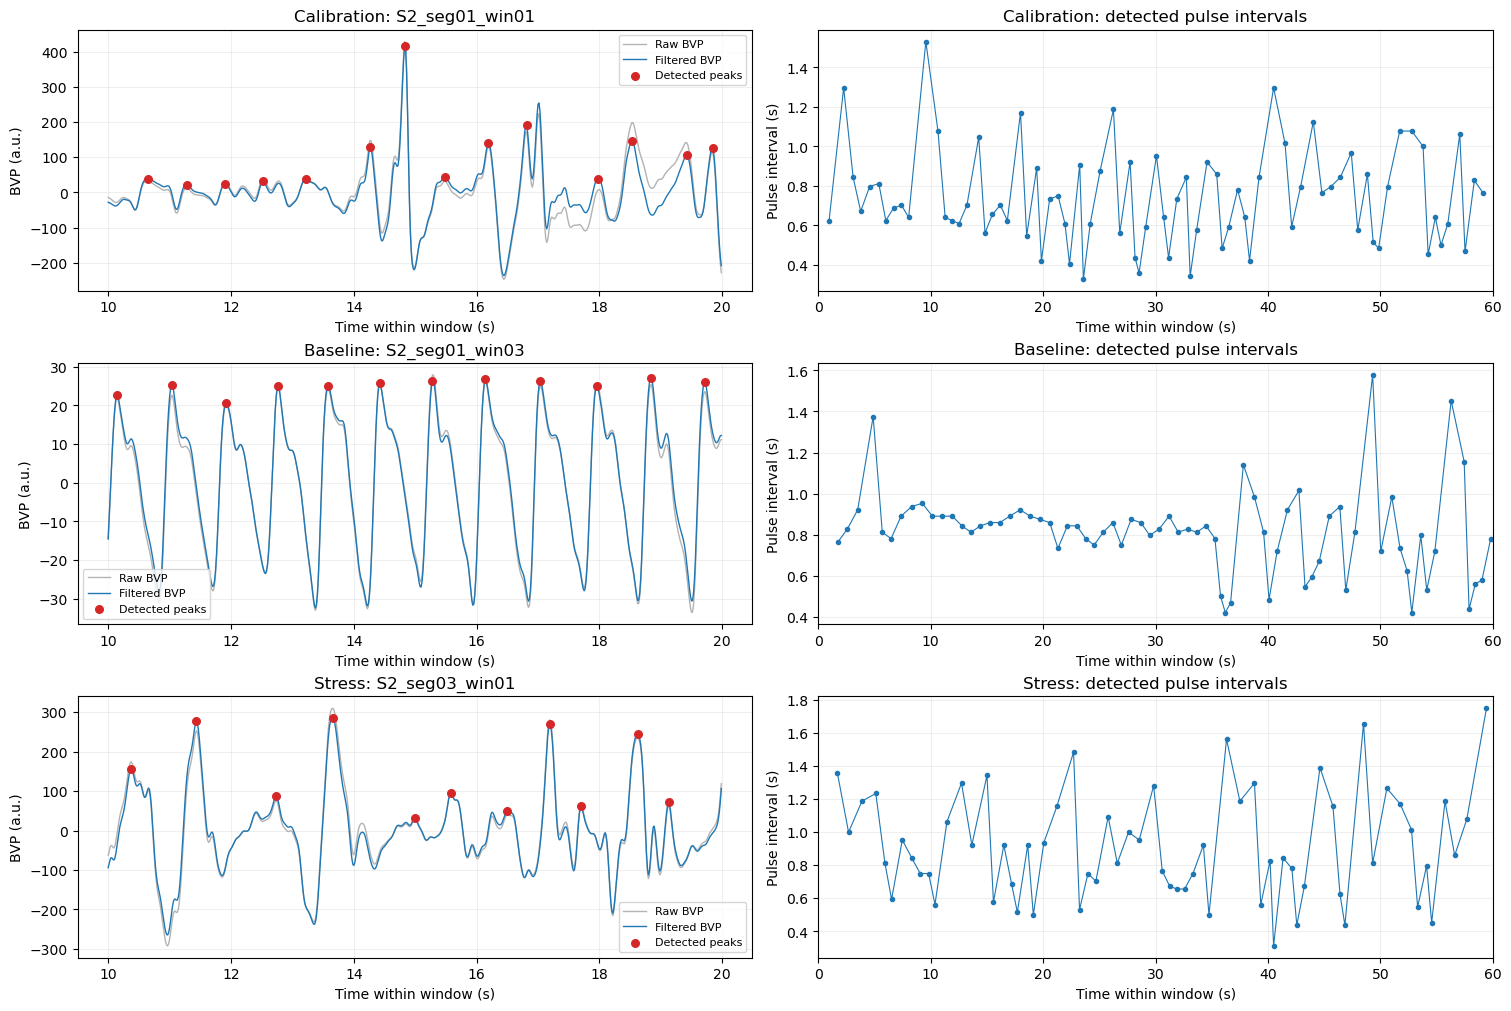

In [27]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 10),
    constrained_layout=True,
)

for row, (role, result) in enumerate(bvp_examples.items()):
    time_s = np.arange(len(result["filtered"])) / BVP_FS

    # Inspect a fixed 10-second excerpt.
    visible = (time_s >= 10) & (time_s < 20)

    peak_times = result["peak_times_s"]
    visible_peaks = result["peaks"][
        (peak_times >= 10) & (peak_times < 20)
    ]

    ax = axes[row, 0]

    ax.plot(
        time_s[visible],
        result["raw"][visible],
        color="0.7",
        linewidth=1,
        label="Raw BVP",
    )

    ax.plot(
        time_s[visible],
        result["filtered"][visible],
        color="tab:blue",
        linewidth=1,
        label="Filtered BVP",
    )

    ax.scatter(
        visible_peaks / BVP_FS,
        result["filtered"][visible_peaks],
        color="tab:red",
        s=30,
        label="Detected peaks",
        zorder=3,
    )

    ax.set_title(f"{role}: {result['window_id']}")
    ax.set_xlabel("Time within window (s)")
    ax.set_ylabel("BVP (a.u.)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

    # Inspect intervals across the entire window.
    ax = axes[row, 1]

    ax.plot(
        peak_times[1:],
        result["intervals_s"],
        marker="o",
        markersize=3,
        linewidth=0.8,
    )

    ax.set_xlim(0, 60)
    ax.set_title(f"{role}: detected pulse intervals")
    ax.set_xlabel("Time within window (s)")
    ax.set_ylabel("Pulse interval (s)")
    ax.grid(alpha=0.2)

plt.show()

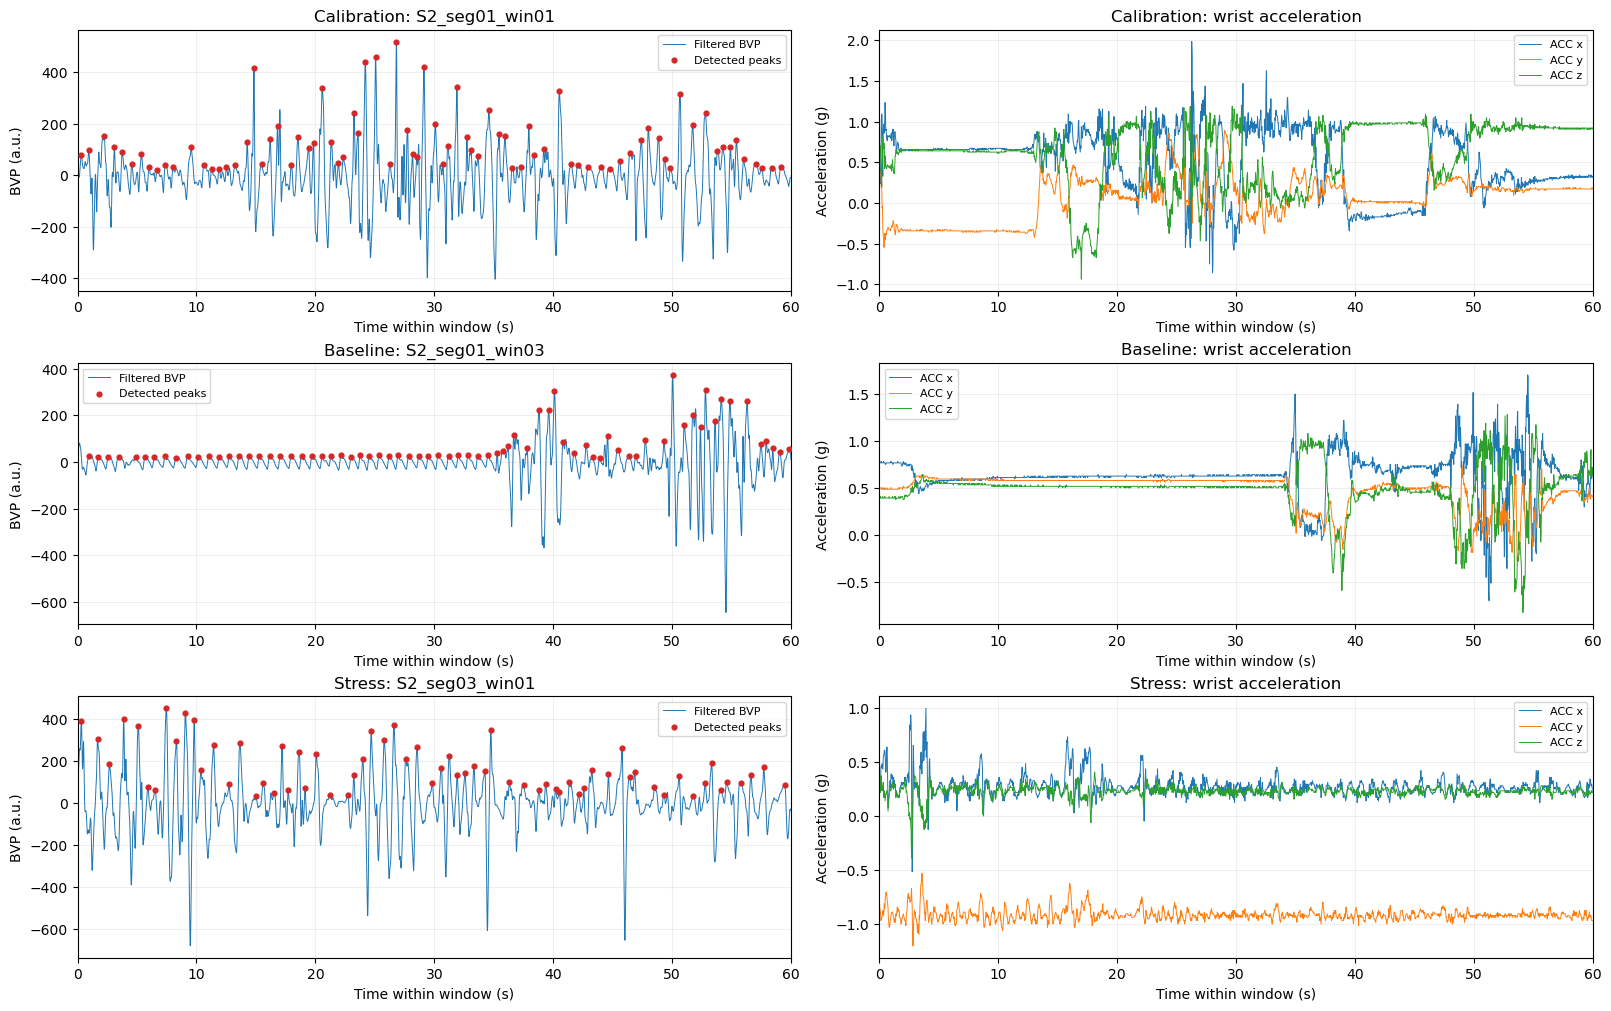

In [28]:
fig, axes = plt.subplots(
    len(bvp_examples),
    2,
    figsize=(16, 10),
    constrained_layout=True,
)

for row, (role, result) in enumerate(bvp_examples.items()):
    window_id = result["window_id"]

    # Plot the entire BVP window and all detected peaks.
    bvp_time_s = np.arange(len(result["filtered"])) / BVP_FS
    peaks = result["peaks"]

    ax = axes[row, 0]

    ax.plot(
        bvp_time_s,
        result["filtered"],
        color="tab:blue",
        linewidth=0.7,
        label="Filtered BVP",
    )

    ax.scatter(
        peaks / BVP_FS,
        result["filtered"][peaks],
        color="tab:red",
        s=12,
        label="Detected peaks",
        zorder=3,
    )

    ax.set_xlim(0, 60)
    ax.set_title(f"{role}: {window_id}")
    ax.set_xlabel("Time within window (s)")
    ax.set_ylabel("BVP (a.u.)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

    # Plot all three acceleration axes in the same time interval.
    acc_g = (
        np.asarray(window_signals[window_id]["ACC"], dtype=float)
        * ACC_SCALE_TO_G
    )
    acc_time_s = np.arange(len(acc_g)) / 32

    ax = axes[row, 1]

    for axis_index, axis_name in enumerate(["x", "y", "z"]):
        ax.plot(
            acc_time_s,
            acc_g[:, axis_index],
            linewidth=0.7,
            label=f"ACC {axis_name}",
        )

    ax.set_xlim(0, 60)
    ax.set_title(f"{role}: wrist acceleration")
    ax.set_xlabel("Time within window (s)")
    ax.set_ylabel("Acceleration (g)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.show()

In [29]:
bvp_diagnostic_rows = []
bvp_results_by_window = {}

for window_id in windows_df["window_id"]:
    row = {
        "window_id": window_id,
        "detection_status": "failed",
        "error_message": "",
        "n_peaks": np.nan,
        "interval_min_s": np.nan,
        "interval_median_s": np.nan,
        "interval_max_s": np.nan,
        "interval_iqr_s": np.nan,
        "peak_span_fraction": np.nan,
        "candidate_rate_mean_bpm": np.nan,
    }

    try:
        result = inspect_bvp_window(
            window_signals[window_id]["BVP"]
        )

        intervals = result["intervals_s"]
        peak_times = result["peak_times_s"]

        q25, q75 = np.percentile(intervals, [25, 75])

        row.update({
            "detection_status": "completed",
            "n_peaks": len(result["peaks"]),
            "interval_min_s": float(intervals.min()),
            "interval_median_s": float(np.median(intervals)),
            "interval_max_s": float(intervals.max()),
            "interval_iqr_s": float(q75 - q25),
            "peak_span_fraction": float(
                (peak_times[-1] - peak_times[0]) / WINDOW_SECONDS
            ),
            "candidate_rate_mean_bpm": float(
                result["pulse_rates_bpm"].mean()
            ),
        })

        bvp_results_by_window[window_id] = result

    except (ValueError, IndexError, RuntimeError) as exc:
        row["error_message"] = (
            f"{type(exc).__name__}: {exc}"
        )

    bvp_diagnostic_rows.append(row)

s2_bvp_diagnostics_df = (
    windows_df[
        [
            "window_id",
            "condition",
            "start_s",
            "calibration_2min",
        ]
    ]
    .merge(
        pd.DataFrame(bvp_diagnostic_rows),
        on="window_id",
        validate="one_to_one",
    )
    .merge(
        s2_basic_df[
            [
                "window_id",
                "ACC_x_std",
                "ACC_y_std",
                "ACC_z_std",
                "ACC_mag_std",
            ]
        ],
        on="window_id",
        validate="one_to_one",
    )
)

display(s2_bvp_diagnostics_df.round(3))

,window_id,condition,start_s,calibration_2min,detection_status,error_message,n_peaks,interval_min_s,interval_median_s,interval_max_s,interval_iqr_s,peak_span_fraction,candidate_rate_mean_bpm,ACC_x_std,ACC_y_std,ACC_z_std,ACC_mag_std
0,S2_seg01_win01,Baseline,306.547,True,completed,,80,0.328,0.703,1.531,0.273,0.980,89.513,0.392,0.266,0.381,0.096
1,S2_seg01_win02,Baseline,366.547,True,completed,,76,0.312,0.812,1.734,0.305,0.974,85.680,0.217,0.145,0.256,0.036
2,S2_seg01_win03,Baseline,426.547,False,completed,,73,0.422,0.828,1.578,0.156,0.980,78.410,0.217,0.178,0.237,0.078
3,S2_seg01_win04,Baseline,486.547,False,completed,,73,0.328,0.828,1.281,0.141,0.982,77.484,0.098,0.072,0.119,0.028
4,S2_seg01_win05,Baseline,546.547,False,completed,,71,0.359,0.828,1.375,0.094,0.966,75.820,0.134,0.101,0.151,0.036
5,S2_seg01_win06,Baseline,606.547,False,completed,,73,0.344,0.844,1.359,0.289,0.977,81.395,0.296,0.165,0.344,0.067
6,S2_seg01_win07,Baseline,666.547,False,completed,,65,0.406,0.836,2.406,0.445,0.984,75.432,0.229,0.105,0.246,0.056
7,S2_seg01_win08,Baseline,726.547,False,completed,,74,0.312,0.828,1.219,0.094,0.988,77.259,0.103,0.056,0.109,0.025
8,S2_seg01_win09,Baseline,786.547,False,completed,,69,0.359,0.844,1.609,0.125,0.969,72.695,0.183,0.085,0.191,0.036
9,S2_seg01_win10,Baseline,846.547,False,completed,,71,0.391,0.844,1.375,0.062,0.978,74.042,0.064,0.090,0.349,0.028


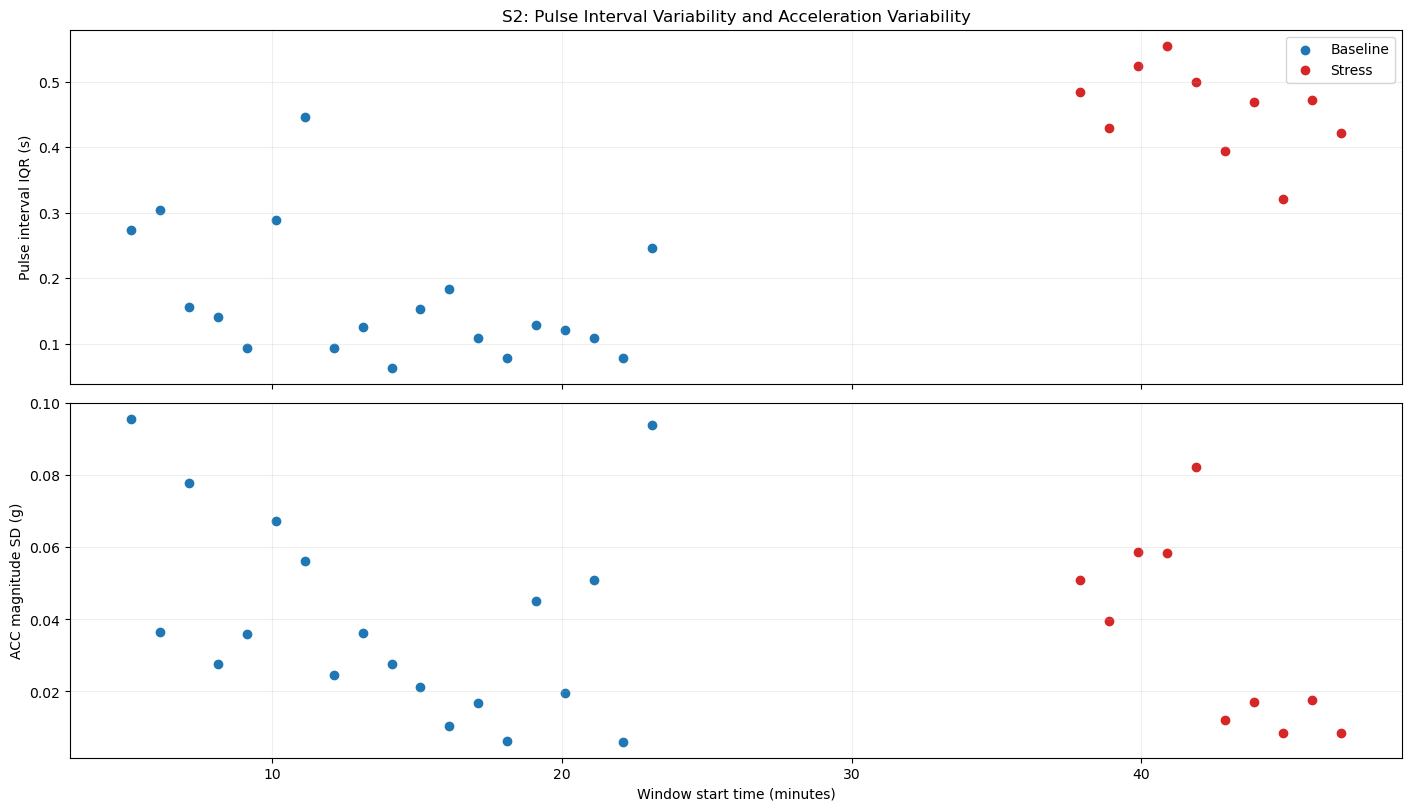

In [30]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    constrained_layout=True,
)

colors = {
    "Baseline": "tab:blue",
    "Stress": "tab:red",
}

for condition, color in colors.items():
    subset = s2_bvp_diagnostics_df.loc[
        s2_bvp_diagnostics_df["condition"] == condition
    ]

    time_min = subset["start_s"] / 60

    axes[0].scatter(
        time_min,
        subset["interval_iqr_s"],
        color=color,
        label=condition,
    )

    axes[1].scatter(
        time_min,
        subset["ACC_mag_std"],
        color=color,
        label=condition,
    )

axes[0].set_ylabel("Pulse interval IQR (s)")
axes[0].set_title(
    "S2: Pulse Interval Variability and Acceleration Variability"
)
axes[0].legend()

axes[1].set_ylabel("ACC magnitude SD (g)")
axes[1].set_xlabel("Window start time (minutes)")

for ax in axes:
    ax.grid(alpha=0.2)

plt.show()

In [31]:
BVP_FEATURE_COLUMNS = [
    "BVP_rate_mean",
    "BVP_rate_std",
    "BVP_rate_min",
    "BVP_rate_max",
    "BVP_interval_sd_ms",
    "BVP_rmssd_ms",
    "BVP_pnn50_pct",
]


def summarize_detected_pulse_intervals(intervals_s):
    """Compute provisional features from uncorrected pulse intervals."""
    intervals_s = np.asarray(intervals_s, dtype=float)

    empty_features = {
        name: np.nan for name in BVP_FEATURE_COLUMNS
    }

    if (
        len(intervals_s) < 2
        or not np.isfinite(intervals_s).all()
        or np.any(intervals_s <= 0)
    ):
        return empty_features

    rates_bpm = 60.0 / intervals_s
    intervals_ms = intervals_s * 1000.0

    # Preserve the original adjacency of detected intervals.
    successive_differences_ms = np.diff(intervals_ms)

    return {
        "BVP_rate_mean": float(np.mean(rates_bpm)),
        "BVP_rate_std": float(np.std(rates_bpm, ddof=1)),
        "BVP_rate_min": float(np.min(rates_bpm)),
        "BVP_rate_max": float(np.max(rates_bpm)),
        "BVP_interval_sd_ms": float(
            np.std(intervals_ms, ddof=1)
        ),
        "BVP_rmssd_ms": float(
            np.sqrt(np.mean(successive_differences_ms ** 2))
        ),
        "BVP_pnn50_pct": float(
            100.0 * np.mean(
                np.abs(successive_differences_ms) > 50.0
            )
        ),
    }


bvp_feature_rows = []

for window_id in windows_df["window_id"]:
    result = bvp_results_by_window.get(window_id)

    if result is None:
        features = {
            name: np.nan for name in BVP_FEATURE_COLUMNS
        }
    else:
        features = summarize_detected_pulse_intervals(
            result["intervals_s"]
        )

    bvp_feature_rows.append({
        "window_id": window_id,
        **features,
    })

bvp_features_df = pd.DataFrame(bvp_feature_rows)

print(
    "BVP features are provisional estimates "
    "from uncorrected detected pulse intervals."
)

display(bvp_features_df.head().round(3))

BVP features are provisional estimates from uncorrected detected pulse intervals.


,window_id,BVP_rate_mean,BVP_rate_std,BVP_rate_min,BVP_rate_max,BVP_interval_sd_ms,BVP_rmssd_ms,BVP_pnn50_pct
0,S2_seg01_win01,89.513,30.246,39.184,182.857,241.960,334.479,87.179
1,S2_seg01_win02,85.680,31.018,34.595,192.000,244.844,297.995,58.108
2,S2_seg01_win03,78.410,21.736,38.020,142.222,207.909,263.624,61.972
3,S2_seg01_win04,77.484,21.607,46.829,182.857,173.687,268.522,76.056
4,S2_seg01_win05,75.820,18.999,43.636,166.957,163.075,271.181,52.174


In [32]:
s2_features_25_df = s2_basic_df.merge(
    bvp_features_df,
    on="window_id",
    how="left",
    validate="one_to_one",
)

feature_columns_25 = (
    basic_feature_columns + BVP_FEATURE_COLUMNS
)

assert len(feature_columns_25) == 25
assert len(s2_features_25_df) == 29

print("Number of windows:", len(s2_features_25_df))
print("Number of candidate features:", len(feature_columns_25))

display(
    s2_features_25_df[
        [
            "window_id",
            "condition",
            "BVP_rate_mean",
            "BVP_interval_sd_ms",
            "BVP_rmssd_ms",
            "BVP_pnn50_pct",
        ]
    ].head().round(3)
)

Number of windows: 29
Number of candidate features: 25


,window_id,condition,BVP_rate_mean,BVP_interval_sd_ms,BVP_rmssd_ms,BVP_pnn50_pct
0,S2_seg01_win01,Baseline,89.513,241.960,334.479,87.179
1,S2_seg01_win02,Baseline,85.680,244.844,297.995,58.108
2,S2_seg01_win03,Baseline,78.410,207.909,263.624,61.972
3,S2_seg01_win04,Baseline,77.484,173.687,268.522,76.056
4,S2_seg01_win05,Baseline,75.820,163.075,271.181,52.174


In [33]:
bvp_feature_summary = pd.DataFrame({
    "missing_count": (
        s2_features_25_df[BVP_FEATURE_COLUMNS].isna().sum()
    ),
    "minimum": (
        s2_features_25_df[BVP_FEATURE_COLUMNS].min()
    ),
    "median": (
        s2_features_25_df[BVP_FEATURE_COLUMNS].median()
    ),
    "maximum": (
        s2_features_25_df[BVP_FEATURE_COLUMNS].max()
    ),
})

display(bvp_feature_summary.round(3))

,missing_count,minimum,median,maximum
BVP_rate_mean,0,69.617,76.917,89.513
BVP_rate_std,0,7.447,27.919,42.809
BVP_rate_min,0,20.870,38.788,49.870
BVP_rate_max,0,98.462,182.857,192.000
BVP_interval_sd_ms,0,88.974,230.551,493.501
BVP_rmssd_ms,0,98.150,297.995,698.544
BVP_pnn50_pct,0,37.313,76.056,90.909


add EDA_scl_mean,EDA_scr_count,EDA_scr_amplitude_mean

In [34]:
EDA_EXTRA_COLUMNS = [
    "EDA_scl_mean",
    "EDA_scr_count",
    "EDA_scr_amplitude_mean",
]


def extract_eda_extra_features(values, fs=4):
    """Extract tonic and SCR features with explicit diagnostic status."""
    features = {
        name: np.nan for name in EDA_EXTRA_COLUMNS
    }

    diagnostics = {
        "eda_decomposition_status": "not_run",
        "eda_scr_status": "not_run",
        "eda_error": "",
        "eda_valid_amplitude_count": 0,
    }

    values = np.asarray(values, dtype=float).reshape(-1)

    if len(values) != 60 * fs or not np.isfinite(values).all():
        diagnostics["eda_error"] = "Incomplete or nonfinite EDA window."
        return features, diagnostics

    # A constant signal requires quality review rather than a zero-SCR assumption.
    if np.ptp(values) == 0:
        diagnostics["eda_error"] = "Constant EDA signal."
        return features, diagnostics

    try:
        components = nk.eda_phasic(
            values,
            sampling_rate=fs,
            method="highpass",
            cutoff=0.05,
        )

        tonic = components["EDA_Tonic"].to_numpy()
        phasic = components["EDA_Phasic"].to_numpy()

        if not (
            np.isfinite(tonic).all()
            and np.isfinite(phasic).all()
        ):
            raise ValueError("Decomposition returned nonfinite values.")

        features["EDA_scl_mean"] = float(np.mean(tonic))
        diagnostics["eda_decomposition_status"] = "completed"

    except (ValueError, IndexError, RuntimeError) as exc:
        diagnostics["eda_decomposition_status"] = "failed"
        diagnostics["eda_error"] = f"{type(exc).__name__}: {exc}"
        return features, diagnostics

    try:
        _, peak_info = nk.eda_peaks(
            phasic,
            sampling_rate=fs,
            method="neurokit",
            amplitude_min=0.1,
        )

        peaks = np.asarray(
            peak_info["SCR_Peaks"], dtype=float
        ).reshape(-1)

        amplitudes = np.asarray(
            peak_info["SCR_Amplitude"], dtype=float
        ).reshape(-1)

        valid_peaks = (
            np.isfinite(peaks)
            & (peaks >= 0)
            & (peaks < len(values))
        )

        n_peaks = int(valid_peaks.sum())
        features["EDA_scr_count"] = n_peaks

        if n_peaks == 0:
            diagnostics["eda_scr_status"] = "no_peaks"
            # Mean response amplitude is undefined when there are no responses.
            return features, diagnostics

        if len(amplitudes) != len(peaks):
            raise ValueError("Peak and amplitude arrays have different lengths.")

        valid_amplitudes = amplitudes[
            valid_peaks
            & np.isfinite(amplitudes)
            & (amplitudes >= 0)
        ]

        diagnostics["eda_valid_amplitude_count"] = len(valid_amplitudes)

        if len(valid_amplitudes) > 0:
            features["EDA_scr_amplitude_mean"] = float(
                np.mean(valid_amplitudes)
            )

        diagnostics["eda_scr_status"] = (
            "completed"
            if len(valid_amplitudes) == n_peaks
            else "incomplete_amplitudes"
        )

    except (ValueError, IndexError, RuntimeError) as exc:
        features["EDA_scr_count"] = np.nan
        features["EDA_scr_amplitude_mean"] = np.nan
        diagnostics["eda_scr_status"] = "failed"
        diagnostics["eda_error"] = f"{type(exc).__name__}: {exc}"

    return features, diagnostics

In [35]:
eda_feature_rows = []
eda_diagnostic_rows = []

for window_id in windows_df["window_id"]:
    features, diagnostics = extract_eda_extra_features(
        window_signals[window_id]["EDA"],
        fs=4,
    )

    eda_feature_rows.append({
        "window_id": window_id,
        **features,
    })

    eda_diagnostic_rows.append({
        "window_id": window_id,
        **diagnostics,
    })

eda_extra_df = pd.DataFrame(eda_feature_rows)
eda_diagnostics_df = pd.DataFrame(eda_diagnostic_rows)

print("SCR extraction status:")
print(
    eda_diagnostics_df["eda_scr_status"]
    .value_counts()
    .to_string()
)

display(eda_extra_df.head(7).round(4))

failed_eda = eda_diagnostics_df.loc[
    eda_diagnostics_df["eda_error"] != ""
]

if not failed_eda.empty:
    print("\nWindows requiring review:")
    display(failed_eda)

SCR extraction status:
eda_scr_status
completed                23
incomplete_amplitudes     6


,window_id,EDA_scl_mean,EDA_scr_count,EDA_scr_amplitude_mean
0,S2_seg01_win01,1.2892,14,0.1079
1,S2_seg01_win02,0.8372,9,0.0279
2,S2_seg01_win03,0.5602,10,0.0308
3,S2_seg01_win04,0.5041,5,0.0268
4,S2_seg01_win05,0.4104,17,0.0037
5,S2_seg01_win06,0.3364,14,0.0102
6,S2_seg01_win07,0.2549,9,0.0080


In [36]:
s2_features_df = s2_features_25_df.merge(
    eda_extra_df,
    on="window_id",
    how="left",
    validate="one_to_one",
)

FEATURE_COLUMNS = (
    basic_feature_columns
    + BVP_FEATURE_COLUMNS
    + EDA_EXTRA_COLUMNS
)

assert len(FEATURE_COLUMNS) == 28
assert len(set(FEATURE_COLUMNS)) == 28
assert len(s2_features_df) == len(windows_df)

print("Subject:", subject_id)
print("Number of windows:", len(s2_features_df))
print("Number of candidate features:", len(FEATURE_COLUMNS))

display(
    s2_features_df[
        [
            "window_id",
            "condition",
            "calibration_2min",
            "EDA_mean",
            "EDA_scl_mean",
            "EDA_scr_count",
            "EDA_scr_amplitude_mean",
        ]
    ].head(7).round(4)
)

display(
    pd.DataFrame({
        "missing_count": s2_features_df[EDA_EXTRA_COLUMNS].isna().sum(),
        "minimum": s2_features_df[EDA_EXTRA_COLUMNS].min(),
        "maximum": s2_features_df[EDA_EXTRA_COLUMNS].max(),
    }).round(4)
)

Subject: S2
Number of windows: 29
Number of candidate features: 28


,window_id,condition,calibration_2min,EDA_mean,EDA_scl_mean,EDA_scr_count,EDA_scr_amplitude_mean
0,S2_seg01_win01,Baseline,True,1.2874,1.2892,14,0.1079
1,S2_seg01_win02,Baseline,True,0.8370,0.8372,9,0.0279
2,S2_seg01_win03,Baseline,False,0.5597,0.5602,10,0.0308
3,S2_seg01_win04,Baseline,False,0.5028,0.5041,5,0.0268
4,S2_seg01_win05,Baseline,False,0.4103,0.4104,17,0.0037
5,S2_seg01_win06,Baseline,False,0.3366,0.3364,14,0.0102
6,S2_seg01_win07,Baseline,False,0.2550,0.2549,9,0.0080


,missing_count,minimum,maximum
EDA_scl_mean,0,0.0926,1.2892
EDA_scr_count,0,5.0000,68.0000
EDA_scr_amplitude_mean,0,0.0021,0.1079


perdsonl calibration


In [37]:
s2_eda_quality_df = (
    windows_df[["window_id", "condition"]]
    .merge(
        eda_extra_df,
        on="window_id",
        validate="one_to_one",
    )
    .merge(
        eda_diagnostics_df,
        on="window_id",
        validate="one_to_one",
    )
)

s2_eda_quality_df["eda_missing_amplitude_count"] = (
    s2_eda_quality_df["EDA_scr_count"]
    - s2_eda_quality_df["eda_valid_amplitude_count"]
)

display(
    s2_eda_quality_df.loc[
        s2_eda_quality_df["eda_scr_status"] == "incomplete_amplitudes",
        [
            "window_id",
            "condition",
            "EDA_scr_count",
            "eda_valid_amplitude_count",
            "eda_missing_amplitude_count",
        ],
    ]
)

,window_id,condition,EDA_scr_count,eda_valid_amplitude_count,eda_missing_amplitude_count
7,S2_seg01_win08,Baseline,33,32,1
12,S2_seg01_win13,Baseline,60,59,1
15,S2_seg01_win16,Baseline,53,52,1
17,S2_seg01_win18,Baseline,51,50,1
19,S2_seg03_win01,Stress,30,29,1
21,S2_seg03_win03,Stress,19,18,1


In [38]:
calibration_mask = s2_features_df["calibration_2min"]

calibration_features = s2_features_df.loc[
    calibration_mask,
    FEATURE_COLUMNS,
].copy()

assert s2_features_df["subject_id"].nunique() == 1
assert len(calibration_features) == 2
assert s2_features_df.loc[calibration_mask, "y"].eq(0).all()

# Compute one personal reference value per feature.
s2_reference_2min = calibration_features.mean(axis=0)

# Record how many calibration windows contributed to each reference.
s2_reference_counts = calibration_features.notna().sum(axis=0)

reference_table = pd.DataFrame({
    "reference_value": s2_reference_2min,
    "valid_calibration_windows": s2_reference_counts,
})

print("Calibration window IDs:")
print(
    s2_features_df.loc[
        calibration_mask, "window_id"
    ].to_string(index=False)
)

display(reference_table.round(4))

Calibration window IDs:
S2_seg01_win01
S2_seg01_win02


,reference_value,valid_calibration_windows
EDA_mean,1.0622,2
EDA_std,0.1385,2
EDA_min,0.8582,2
EDA_max,1.3817,2
EDA_slope,-0.0069,2
TEMP_mean,35.7551,2
TEMP_std,0.0258,2
TEMP_min,35.7050,2
TEMP_max,35.8100,2
TEMP_slope,-0.0005,2


In [39]:
# Both versions use exactly the same classification windows.
s2_uncalibrated_df = s2_features_df.loc[
    ~calibration_mask
].copy()

s2_calibrated_df = s2_uncalibrated_df.copy()

# Subtract the matching personal reference from each feature.
s2_calibrated_df[FEATURE_COLUMNS] = (
    s2_uncalibrated_df[FEATURE_COLUMNS]
    .subtract(s2_reference_2min, axis="columns")
)

assert s2_uncalibrated_df["window_id"].equals(
    s2_calibrated_df["window_id"]
)

assert s2_uncalibrated_df["y"].equals(
    s2_calibrated_df["y"]
)

print("Uncalibrated classification windows:", len(s2_uncalibrated_df))
print("Calibrated classification windows:", len(s2_calibrated_df))
print("Features per window:", len(FEATURE_COLUMNS))

print("\nClass counts:")
print(
    s2_calibrated_df.groupby("condition").size().to_string()
)

Uncalibrated classification windows: 27
Calibrated classification windows: 27
Features per window: 28

Class counts:
condition
Baseline    17
Stress      10


In [40]:
example_id = s2_uncalibrated_df.iloc[0]["window_id"]

selected_features = [
    "EDA_mean",
    "TEMP_mean",
    "ACC_mag_std",
    "BVP_rate_mean",
    "EDA_scr_count",
]

before = s2_uncalibrated_df.set_index("window_id").loc[
    example_id, selected_features
].astype(float)

after = s2_calibrated_df.set_index("window_id").loc[
    example_id, selected_features
].astype(float)

comparison_df = pd.DataFrame({
    "original_value": before,
    "personal_reference": s2_reference_2min.loc[selected_features],
    "adjusted_value": after,
})

print("Example window:", example_id)
display(comparison_df.round(4))

Example window: S2_seg01_win03


,original_value,personal_reference,adjusted_value
EDA_mean,0.5597,1.0622,-0.5025
TEMP_mean,35.7977,35.7551,0.0426
ACC_mag_std,0.0780,0.0660,0.0120
BVP_rate_mean,78.4097,87.5961,-9.1864
EDA_scr_count,10.0000,11.5000,-1.5000


In [41]:
import gc
import pickle
import numpy as np
import pandas as pd

SUBJECT_IDS = [
    "S2", "S3", "S4", "S5", "S6",
    "S7", "S8", "S9", "S10", "S11",
    "S13", "S14", "S15", "S16", "S17",
]

required_functions = [
    "extract_basic_features",
    "extract_acc_features",
    "inspect_bvp_window",
    "summarize_detected_pulse_intervals",
    "extract_eda_extra_features",
]

missing_functions = [
    name for name in required_functions
    if not callable(globals().get(name))
]

if missing_functions:
    raise RuntimeError(
        f"Run the earlier function-definition cells first: {missing_functions}"
    )

assert len(FEATURE_COLUMNS) == 28
assert len(set(FEATURE_COLUMNS)) == 28

OUTPUT_DIR = DATA_DIR / "outputs_jacklyn"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Required functions are available.")
print(f"Number of subjects: {len(SUBJECT_IDS)}")
print(f"Number of candidate features: {len(FEATURE_COLUMNS)}")

Required functions are available.
Number of subjects: 15
Number of candidate features: 28


In [42]:
def process_subject(subject_id, data_dir):
    label_fs = 700
    window_seconds = 60
    window_label_samples = window_seconds * label_fs

    sampling_rates = {
        "BVP": 64,
        "EDA": 4,
        "TEMP": 4,
        "ACC": 32,
    }

    file_path = data_dir / subject_id / f"{subject_id}.pkl"

    with file_path.open("rb") as file:
        subject_data = pickle.load(file, encoding="latin1")

    subject_labels = np.asarray(subject_data["label"]).reshape(-1)
    subject_wrist = subject_data["signal"]["wrist"]

    arrays = {
        name: np.asarray(subject_wrist[name])
        for name in sampling_rates
    }

    for name in ["BVP", "EDA", "TEMP"]:
        arrays[name] = arrays[name].reshape(-1)

    if arrays["ACC"].ndim != 2 or arrays["ACC"].shape[1] != 3:
        raise ValueError(f"{subject_id}: unexpected ACC shape.")

    # Release the chest data while keeping the wrist arrays and labels.
    del subject_wrist, subject_data

    changes = np.flatnonzero(
        subject_labels[1:] != subject_labels[:-1]
    ) + 1

    edges = np.r_[0, changes, len(subject_labels)]

    baseline_segments = [
        (int(start), int(end))
        for start, end in zip(edges[:-1], edges[1:])
        if subject_labels[start] == 1
    ]

    if not baseline_segments:
        raise ValueError(f"{subject_id}: no baseline interval found.")

    initial_baseline_start, initial_baseline_end = baseline_segments[0]

    if initial_baseline_end - initial_baseline_start < 300 * label_fs:
        raise ValueError(
            f"{subject_id}: initial baseline is shorter than five minutes."
        )

    feature_rows = []
    quality_rows = []
    interval_rows = []

    for segment_id, (segment_start, segment_end) in enumerate(
        zip(edges[:-1], edges[1:])
    ):
        original_label = int(subject_labels[segment_start])

        if original_label not in (1, 2):
            continue

        condition = "Baseline" if original_label == 1 else "Stress"
        segment_samples = int(segment_end - segment_start)
        n_windows = segment_samples // window_label_samples

        interval_rows.append({
            "subject_id": subject_id,
            "segment_id": segment_id,
            "condition": condition,
            "duration_s": segment_samples / label_fs,
            "complete_windows": n_windows,
            "unused_tail_s": (
                segment_samples % window_label_samples
            ) / label_fs,
        })

        for window_number in range(n_windows):
            start_idx = int(
                segment_start + window_number * window_label_samples
            )
            end_idx = start_idx + window_label_samples

            if not np.all(
                subject_labels[start_idx:end_idx] == original_label
            ):
                raise ValueError(f"{subject_id}: mixed-label window.")

            window_id = (
                f"{subject_id}_seg{segment_id:02d}"
                f"_win{window_number + 1:02d}"
            )

            chunks = {}

            for name, fs in sampling_rates.items():
                signal_start = (start_idx * fs + label_fs - 1) // label_fs
                signal_end = (end_idx * fs + label_fs - 1) // label_fs

                if signal_end > len(arrays[name]):
                    raise ValueError(
                        f"{window_id}: insufficient {name} coverage."
                    )

                chunk = arrays[name][signal_start:signal_end]

                if len(chunk) != window_seconds * fs:
                    raise ValueError(
                        f"{window_id}: unexpected {name} window length."
                    )

                chunks[name] = chunk

            is_initial_baseline = (
                original_label == 1
                and segment_start == initial_baseline_start
            )

            metadata = {
                "subject_id": subject_id,
                "window_id": window_id,
                "condition": condition,
                "y": int(original_label == 2),
                "start_s": start_idx / label_fs,
                "end_s": end_idx / label_fs,
                "duration_s": window_seconds,
                "calibration_2min": (
                    is_initial_baseline and window_number < 2
                ),
                "calibration_5min": (
                    is_initial_baseline and window_number < 5
                ),
                "nonfinite_values": sum(
                    int(np.count_nonzero(~np.isfinite(chunk)))
                    for chunk in chunks.values()
                ),
            }

            features = {}
            quality = {
                "subject_id": subject_id,
                "window_id": window_id,
                "condition": condition,
            }

            features.update(
                extract_basic_features(chunks["EDA"], 4, "EDA")
            )
            features.update(
                extract_basic_features(chunks["TEMP"], 4, "TEMP")
            )
            features.update(
                extract_acc_features(chunks["ACC"], 1.0 / 64.0)
            )

            # Preserve uncorrected BVP features as candidates.
            features.update({
                name: np.nan for name in BVP_FEATURE_COLUMNS
            })

            try:
                bvp_result = inspect_bvp_window(chunks["BVP"], fs=64)
                intervals = bvp_result["intervals_s"]

                features.update(
                    summarize_detected_pulse_intervals(intervals)
                )

                quality.update({
                    "bvp_detection_status": "completed",
                    "bvp_error": "",
                    "bvp_n_peaks": len(bvp_result["peaks"]),
                    "bvp_interval_min_s": np.min(intervals),
                    "bvp_interval_max_s": np.max(intervals),
                })

            except (ValueError, IndexError, RuntimeError) as error:
                quality.update({
                    "bvp_detection_status": "failed",
                    "bvp_error": str(error),
                    "bvp_n_peaks": np.nan,
                    "bvp_interval_min_s": np.nan,
                    "bvp_interval_max_s": np.nan,
                })

            eda_features, eda_diagnostics = extract_eda_extra_features(
                chunks["EDA"], fs=4
            )

            features.update(eda_features)
            quality.update(eda_diagnostics)

            missing_names = set(FEATURE_COLUMNS) - set(features)

            if missing_names:
                raise ValueError(
                    f"{window_id}: missing feature keys: {missing_names}"
                )

            feature_rows.append({
                **metadata,
                **{name: features[name] for name in FEATURE_COLUMNS},
            })
            quality_rows.append(quality)

    features_df = pd.DataFrame(feature_rows)
    quality_df = pd.DataFrame(quality_rows)
    intervals_df = pd.DataFrame(interval_rows)

    if features_df.empty:
        raise ValueError(f"{subject_id}: no complete windows.")

    assert features_df["window_id"].is_unique
    assert features_df["calibration_2min"].sum() == 2
    assert features_df["calibration_5min"].sum() == 5
    assert set(features_df["y"]) == {0, 1}

    return features_df, quality_df, intervals_df

In [43]:
s2_batch_features, s2_batch_quality, s2_batch_intervals = process_subject(
    "S2", DATA_DIR
)

previous = (
    s2_features_df
    .set_index("window_id")
    .sort_index()
)

recomputed = (
    s2_batch_features
    .set_index("window_id")
    .sort_index()
)

pd.testing.assert_index_equal(previous.index, recomputed.index)

np.testing.assert_allclose(
    previous[FEATURE_COLUMNS].to_numpy(dtype=float),
    recomputed[FEATURE_COLUMNS].to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-9,
    equal_nan=True,
)

for column in ["y", "calibration_2min", "calibration_5min"]:
    np.testing.assert_array_equal(
        previous[column].to_numpy(),
        recomputed[column].to_numpy(),
    )

print("S2 validation passed.")
print("Batch processing reproduces the existing S2 features.")

S2 validation passed.
Batch processing reproduces the existing S2 features.


In [44]:
all_feature_tables = []
all_quality_tables = []
all_interval_tables = []

for subject_id in SUBJECT_IDS:
    if subject_id == "S2":
        subject_features = s2_batch_features.copy()
        subject_quality = s2_batch_quality.copy()
        subject_intervals = s2_batch_intervals.copy()
    else:
        subject_features, subject_quality, subject_intervals = (
            process_subject(subject_id, DATA_DIR)
        )

    subject_features.to_csv(
        OUTPUT_DIR / f"{subject_id}_candidate_features.csv",
        index=False,
    )
    subject_quality.to_csv(
        OUTPUT_DIR / f"{subject_id}_quality.csv",
        index=False,
    )

    all_feature_tables.append(subject_features)
    all_quality_tables.append(subject_quality)
    all_interval_tables.append(subject_intervals)

    counts = subject_features["condition"].value_counts()

    print(
        f"{subject_id}: "
        f"{len(subject_features)} windows | "
        f"Baseline = {counts.get('Baseline', 0)} | "
        f"Stress = {counts.get('Stress', 0)}"
    )

    gc.collect()

all_features_df = pd.concat(all_feature_tables, ignore_index=True)
all_quality_df = pd.concat(all_quality_tables, ignore_index=True)
all_intervals_df = pd.concat(all_interval_tables, ignore_index=True)

assert all_features_df["subject_id"].nunique() == 15
assert all_features_df["window_id"].is_unique

all_features_df.to_csv(
    OUTPUT_DIR / "all_subjects_candidate_features.csv", index=False
)
all_quality_df.to_csv(
    OUTPUT_DIR / "all_subjects_quality.csv", index=False
)
all_intervals_df.to_csv(
    OUTPUT_DIR / "all_subjects_intervals.csv", index=False
)

print("\nAll subjects processed successfully.")

S2: 29 windows | Baseline = 19 | Stress = 10
S3: 29 windows | Baseline = 19 | Stress = 10
S4: 29 windows | Baseline = 19 | Stress = 10
S5: 29 windows | Baseline = 19 | Stress = 10
S6: 29 windows | Baseline = 19 | Stress = 10
S7: 29 windows | Baseline = 19 | Stress = 10
S8: 30 windows | Baseline = 19 | Stress = 11
S9: 29 windows | Baseline = 19 | Stress = 10
S10: 31 windows | Baseline = 19 | Stress = 12
S11: 30 windows | Baseline = 19 | Stress = 11
S13: 30 windows | Baseline = 19 | Stress = 11
S14: 30 windows | Baseline = 19 | Stress = 11
S15: 30 windows | Baseline = 19 | Stress = 11
S16: 30 windows | Baseline = 19 | Stress = 11
S17: 31 windows | Baseline = 19 | Stress = 12

All subjects processed successfully.


In [45]:
calibration_rows = all_features_df.loc[
    all_features_df["calibration_2min"]
].copy()

reference_2min_df = (
    calibration_rows
    .groupby("subject_id")[FEATURE_COLUMNS]
    .mean()
)

reference_counts_df = (
    calibration_rows
    .groupby("subject_id")[FEATURE_COLUMNS]
    .count()
)

uncalibrated_df = all_features_df.loc[
    ~all_features_df["calibration_2min"]
].copy().reset_index(drop=True)

calibrated_2min_df = uncalibrated_df.copy()

# Match each classification window to its own subject's reference.
matched_references = reference_2min_df.loc[
    uncalibrated_df["subject_id"].to_numpy(),
    FEATURE_COLUMNS,
].to_numpy(dtype=float)

calibrated_2min_df[FEATURE_COLUMNS] = (
    uncalibrated_df[FEATURE_COLUMNS].to_numpy(dtype=float)
    - matched_references
)

assert uncalibrated_df["window_id"].equals(
    calibrated_2min_df["window_id"]
)
assert uncalibrated_df["y"].equals(calibrated_2min_df["y"])

uncalibrated_df.to_csv(
    OUTPUT_DIR / "classification_uncalibrated.csv", index=False
)
calibrated_2min_df.to_csv(
    OUTPUT_DIR / "classification_calibrated_2min.csv", index=False
)
reference_2min_df.to_csv(
    OUTPUT_DIR / "personal_references_2min.csv"
)
reference_counts_df.to_csv(
    OUTPUT_DIR / "personal_reference_counts_2min.csv"
)

print("Classification windows per subject:")
display(
    uncalibrated_df.groupby(["subject_id", "condition"])
    .size()
    .unstack(fill_value=0)
    .reindex(SUBJECT_IDS)
)

print("Missing feature values:")
display(
    pd.DataFrame({
        "uncalibrated": uncalibrated_df[FEATURE_COLUMNS].isna().sum(),
        "calibrated_2min": calibrated_2min_df[FEATURE_COLUMNS].isna().sum(),
    })
)

print("BVP detection status:")
print(all_quality_df["bvp_detection_status"].value_counts(dropna=False))

print("\nEDA SCR extraction status:")
print(all_quality_df["eda_scr_status"].value_counts(dropna=False))

Classification windows per subject:


condition,Baseline,Stress
subject_id,,
S2,17,10
S3,17,10
S4,17,10
S5,17,10
S6,17,10
S7,17,10
S8,17,11
S9,17,10
S10,17,12


Missing feature values:


,uncalibrated,calibrated_2min
EDA_mean,0,0
EDA_std,0,0
EDA_min,0,0
EDA_max,0,0
EDA_slope,0,0
TEMP_mean,0,0
TEMP_std,0,0
TEMP_min,0,0
TEMP_max,0,0
TEMP_slope,0,0


BVP detection status:
bvp_detection_status
completed    445
Name: count, dtype: int64

EDA SCR extraction status:
eda_scr_status
completed                351
incomplete_amplitudes     94
Name: count, dtype: int64


Model Training

In [46]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
)

RANDOM_STATE = 42

models = {
    "DT": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "LDA": LinearDiscriminantAnalysis(),
    "RF": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

def make_model_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", clone(estimator)),
    ])

print("Models are ready: DT, LDA, RF.")

Models are ready: DT, LDA, RF.


LOSO

In [47]:
def run_loso(dataframe, feature_columns, model_dict, configuration):
    df = dataframe.copy().reset_index(drop=True)

    assert df["window_id"].is_unique
    assert not df["calibration_2min"].any()
    assert set(df["subject_id"]) == set(SUBJECT_IDS)

    score_rows = []
    prediction_tables = []

    for held_out_subject in SUBJECT_IDS:
        test_mask = df["subject_id"].eq(held_out_subject)

        train_df = df.loc[~test_mask]
        test_df = df.loc[test_mask]

        assert train_df["subject_id"].nunique() == 14
        assert test_df["subject_id"].nunique() == 1

        X_train = (
            train_df[feature_columns]
            .astype(float)
            .replace([np.inf, -np.inf], np.nan)
        )
        X_test = (
            test_df[feature_columns]
            .astype(float)
            .replace([np.inf, -np.inf], np.nan)
        )

        y_train = train_df["y"].astype(int)
        y_test = test_df["y"].astype(int)

        assert set(y_train.unique()) == {0, 1}
        assert set(y_test.unique()) == {0, 1}

        # Stop rather than silently dropping an entirely missing feature.
        empty_features = X_train.columns[
            X_train.isna().all()
        ].tolist()

        if empty_features:
            raise ValueError(
                f"{held_out_subject}: entirely missing training features: "
                f"{empty_features}"
            )

        for model_name, estimator in model_dict.items():
            pipeline = make_model_pipeline(estimator)

            pipeline.fit(X_train, y_train)
            y_pred = pipeline.predict(X_test)

            tn, fp, fn, tp = confusion_matrix(
                y_test, y_pred, labels=[0, 1]
            ).ravel()

            score_rows.append({
                "configuration": configuration,
                "model": model_name,
                "held_out_subject": held_out_subject,
                "n_train": len(train_df),
                "n_test": len(test_df),
                "balanced_accuracy": balanced_accuracy_score(
                    y_test, y_pred
                ),
                "stress_f1": f1_score(
                    y_test, y_pred, pos_label=1, zero_division=0
                ),
                "stress_recall": recall_score(
                    y_test, y_pred, pos_label=1, zero_division=0
                ),
                "tn": int(tn),
                "fp": int(fp),
                "fn": int(fn),
                "tp": int(tp),
            })

            predictions = test_df[
                ["subject_id", "window_id", "condition", "y"]
            ].copy()

            predictions = predictions.rename(columns={"y": "y_true"})
            predictions["y_pred"] = y_pred
            predictions["configuration"] = configuration
            predictions["model"] = model_name

            prediction_tables.append(predictions)

        print(
            f"{configuration} | Test subject: {held_out_subject} | "
            f"Train windows: {len(train_df)} | "
            f"Test windows: {len(test_df)} | Completed"
        )

    return (
        pd.DataFrame(score_rows),
        pd.concat(prediction_tables, ignore_index=True),
    )

In [48]:
comparison_columns = ["subject_id", "window_id", "y"]

pd.testing.assert_frame_equal(
    uncalibrated_df[comparison_columns].reset_index(drop=True),
    calibrated_2min_df[comparison_columns].reset_index(drop=True),
)

print(f"Classification windows: {len(uncalibrated_df)}")
print(f"Candidate features: {len(FEATURE_COLUMNS)}")

scores_uncalibrated, predictions_uncalibrated = run_loso(
    dataframe=uncalibrated_df,
    feature_columns=FEATURE_COLUMNS,
    model_dict=models,
    configuration="Uncalibrated",
)

scores_calibrated, predictions_calibrated = run_loso(
    dataframe=calibrated_2min_df,
    feature_columns=FEATURE_COLUMNS,
    model_dict=models,
    configuration="Calibrated_2min",
)

loso_scores_df = pd.concat(
    [scores_uncalibrated, scores_calibrated],
    ignore_index=True,
)

loso_predictions_df = pd.concat(
    [predictions_uncalibrated, predictions_calibrated],
    ignore_index=True,
)

assert len(loso_scores_df) == 90

assert not loso_predictions_df.duplicated(
    ["configuration", "model", "window_id"]
).any()

assert len(loso_predictions_df) == len(uncalibrated_df) * 6

loso_scores_df.to_csv(
    OUTPUT_DIR / "exploratory_loso_scores_28features.csv",
    index=False,
)

loso_predictions_df.to_csv(
    OUTPUT_DIR / "exploratory_loso_predictions_28features.csv",
    index=False,
)

print("\nAll 90 model fits completed.")
print("Scores and predictions saved.")

Classification windows: 415
Candidate features: 28
Uncalibrated | Test subject: S2 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S3 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S4 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S5 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S6 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S7 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S8 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test subject: S9 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S10 | Train windows: 386 | Test windows: 29 | Completed
Uncalibrated | Test subject: S11 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test subject: S13 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test su

In [49]:
summary_df = (
    loso_scores_df
    .groupby(["configuration", "model"], sort=False)
    .agg(
        n_subjects=("held_out_subject", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        stress_f1_mean=("stress_f1", "mean"),
        stress_f1_sd=("stress_f1", "std"),
        stress_recall_mean=("stress_recall", "mean"),
        stress_recall_sd=("stress_recall", "std"),
    )
    .reset_index()
)

summary_df.to_csv(
    OUTPUT_DIR / "exploratory_loso_summary_28features.csv",
    index=False,
)

display(summary_df.round(3))

,configuration,model,n_subjects,balanced_accuracy_mean,balanced_accuracy_sd,stress_f1_mean,stress_f1_sd,stress_recall_mean,stress_recall_sd
0,Uncalibrated,DT,15,0.820,0.154,0.795,0.163,0.879,0.191
1,Uncalibrated,LDA,15,0.917,0.097,0.890,0.132,0.884,0.199
2,Uncalibrated,RF,15,0.886,0.138,0.837,0.253,0.839,0.267
3,Calibrated_2min,DT,15,0.935,0.098,0.920,0.117,0.956,0.125
4,Calibrated_2min,LDA,15,0.913,0.111,0.881,0.181,0.846,0.229
5,Calibrated_2min,RF,15,0.933,0.145,0.892,0.247,0.893,0.286


In [50]:
paired_ba_df = (
    loso_scores_df
    .pivot(
        index=["model", "held_out_subject"],
        columns="configuration",
        values="balanced_accuracy",
    )
    .reset_index()
)

paired_ba_df.columns.name = None

paired_ba_df["change"] = (
    paired_ba_df["Calibrated_2min"]
    - paired_ba_df["Uncalibrated"]
)

paired_ba_df["change_percentage_points"] = (
    paired_ba_df["change"] * 100
)

tolerance = 1e-10

paired_ba_df["outcome"] = np.select(
    [
        paired_ba_df["change"] > tolerance,
        paired_ba_df["change"] < -tolerance,
    ],
    ["Improved", "Worsened"],
    default="Unchanged",
)

change_summary_df = (
    paired_ba_df
    .groupby("model")
    .agg(
        n_subjects=("held_out_subject", "nunique"),
        mean_change_pp=("change_percentage_points", "mean"),
        median_change_pp=("change_percentage_points", "median"),
        largest_drop_pp=("change_percentage_points", "min"),
        largest_gain_pp=("change_percentage_points", "max"),
    )
)

outcome_counts = (
    pd.crosstab(
        paired_ba_df["model"],
        paired_ba_df["outcome"],
    )
    .reindex(
        columns=["Improved", "Unchanged", "Worsened"],
        fill_value=0,
    )
)

change_summary_df = change_summary_df.join(outcome_counts)

print("Effect of calibration on balanced accuracy:")
display(change_summary_df.round(3))

print("Changes for individual subjects, in percentage points:")
display(
    paired_ba_df.pivot(
        index="held_out_subject",
        columns="model",
        values="change_percentage_points",
    )
    .reindex(SUBJECT_IDS)
    .round(2)
)

paired_ba_df.to_csv(
    OUTPUT_DIR / "exploratory_calibration_paired_changes.csv",
    index=False,
)

Effect of calibration on balanced accuracy:


,n_subjects,mean_change_pp,median_change_pp,largest_drop_pp,largest_gain_pp,Improved,Unchanged,Worsened
model,,,,,,,,
DT,15,11.501,11.765,-14.706,42.402,9,4,2
LDA,15,-0.361,0.000,-24.599,30.000,6,2,7
RF,15,4.643,4.545,-17.647,20.000,10,3,2


Changes for individual subjects, in percentage points:


model,DT,LDA,RF
held_out_subject,,,
S2,12.94,5.00,15.00
S3,25.29,-22.06,-5.59
S4,0.00,-8.82,0.00
S5,-14.71,-5.00,5.00
S6,10.00,10.00,2.94
S7,17.65,11.76,8.82
S8,0.00,0.00,9.09
S9,21.18,30.00,20.00
S10,35.29,-9.56,2.94


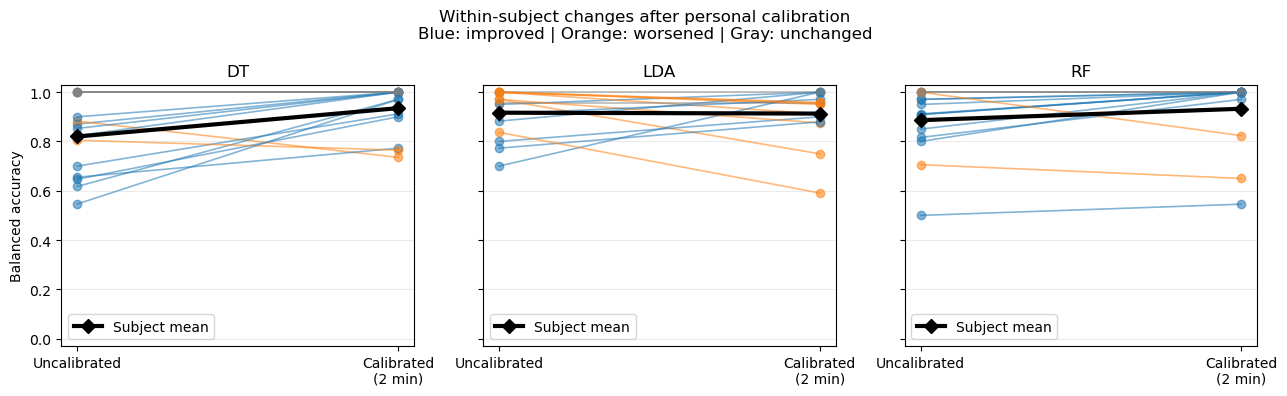

In [51]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharey=True,
)

for ax, model_name in zip(axes, ["DT", "LDA", "RF"]):
    model_results = (
        paired_ba_df.loc[paired_ba_df["model"].eq(model_name)]
        .set_index("held_out_subject")
        .reindex(SUBJECT_IDS)
    )

    for subject_id, row in model_results.iterrows():
        if row["change"] > tolerance:
            color = "tab:blue"
        elif row["change"] < -tolerance:
            color = "tab:orange"
        else:
            color = "gray"

        ax.plot(
            [0, 1],
            [row["Uncalibrated"], row["Calibrated_2min"]],
            marker="o",
            color=color,
            alpha=0.55,
            linewidth=1.2,
        )

    means = model_results[
        ["Uncalibrated", "Calibrated_2min"]
    ].mean()

    ax.plot(
        [0, 1],
        means.to_numpy(),
        color="black",
        marker="D",
        linewidth=3,
        markersize=7,
        label="Subject mean",
        zorder=10,
    )

    ax.set_title(model_name)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Uncalibrated", "Calibrated\n(2 min)"])
    ax.set_ylim(-0.03, 1.03)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower left")

axes[0].set_ylabel("Balanced accuracy")

fig.suptitle(
    "Within-subject changes after personal calibration\n"
    "Blue: improved | Orange: worsened | Gray: unchanged"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "exploratory_calibration_paired_changes.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [52]:
lowest_recall_df = (
    loso_scores_df
    .sort_values(
        ["configuration", "model", "stress_recall", "balanced_accuracy"]
    )
    .groupby(["configuration", "model"], sort=False)
    .head(3)
)

print("Three lowest stress-recall subjects per configuration and model:")

display(
    lowest_recall_df[
        [
            "configuration",
            "model",
            "held_out_subject",
            "balanced_accuracy",
            "stress_f1",
            "stress_recall",
            "fn",
            "tp",
        ]
    ].round(3)
)

Three lowest stress-recall subjects per configuration and model:


,configuration,model,held_out_subject,balanced_accuracy,stress_f1,stress_recall,fn,tp
78,Calibrated_2min,DT,S14,0.773,0.706,0.545,5,6
48,Calibrated_2min,DT,S3,0.900,0.889,0.800,2,8
54,Calibrated_2min,DT,S5,0.735,0.690,1.000,0,10
82,Calibrated_2min,LDA,S15,0.591,0.308,0.182,9,2
49,Calibrated_2min,LDA,S3,0.750,0.667,0.500,5,5
70,Calibrated_2min,LDA,S10,0.875,0.857,0.750,3,9
80,Calibrated_2min,RF,S14,0.545,0.167,0.091,10,1
50,Calibrated_2min,RF,S3,0.650,0.462,0.300,7,3
83,Calibrated_2min,RF,S15,0.824,0.786,1.000,0,11
21,Uncalibrated,DT,S9,0.700,0.571,0.400,6,4


Personal calibration did not benefit every participant: performance decreased across all three models for S15. Despite its high average balanced accuracy, the calibrated RF detected only 1 of 11 stress windows for S14, highlighting substantial individual differences in detection performance.

## How well can wrist-based physiological features distinguish stress from baseline in previously unseen subjects?
### In this exploratory WESAD analysis, mean balanced accuracy ranged from 82.0% to 91.7% without calibration and from 91.3% to 93.5% after two-minute personal calibration. Calibration improved the average performance of DT and RF but not LDA. However, some participants still experienced reduced performance or substantial under-detection of stress.

# RQ2: Which wrist-based signals contribute most to stress-versus-baseline classification?

Performance drop = Full balanced accuracy − Reduced balanced accuracy

In [53]:
SIGNAL_NAMES = ["BVP", "EDA", "TEMP", "ACC"]

signal_feature_groups = {
    signal: [
        feature for feature in FEATURE_COLUMNS
        if feature.startswith(f"{signal}_")
    ]
    for signal in SIGNAL_NAMES
}

grouped_features = [
    feature
    for features in signal_feature_groups.values()
    for feature in features
]

assert len(grouped_features) == len(FEATURE_COLUMNS)
assert set(grouped_features) == set(FEATURE_COLUMNS)

ablation_feature_sets = {
    f"Without_{signal}": [
        feature for feature in FEATURE_COLUMNS
        if feature not in signal_feature_groups[signal]
    ]
    for signal in SIGNAL_NAMES
}

configuration_rows = [{
    "configuration": "Full",
    "removed_signal": "None",
    "n_features": len(FEATURE_COLUMNS),
}]

for signal in SIGNAL_NAMES:
    configuration_rows.append({
        "configuration": f"Without_{signal}",
        "removed_signal": signal,
        "n_features": len(ablation_feature_sets[f"Without_{signal}"]),
    })

display(pd.DataFrame(configuration_rows))

,configuration,removed_signal,n_features
0,Full,None,28
1,Without_BVP,BVP,21
2,Without_EDA,EDA,20
3,Without_TEMP,TEMP,23
4,Without_ACC,ACC,20


In [54]:
full_scores = loso_scores_df.loc[
    loso_scores_df["configuration"].eq("Calibrated_2min")
].copy()

full_predictions = loso_predictions_df.loc[
    loso_predictions_df["configuration"].eq("Calibrated_2min")
].copy()

assert len(full_scores) == 45
assert len(full_predictions) == len(calibrated_2min_df) * 3

full_scores["configuration"] = "Full"
full_predictions["configuration"] = "Full"

ablation_score_tables = [full_scores]
ablation_prediction_tables = [full_predictions]

for configuration, selected_features in ablation_feature_sets.items():
    print(
        f"\nStarting {configuration}: "
        f"{len(selected_features)} features"
    )

    config_scores, config_predictions = run_loso(
        dataframe=calibrated_2min_df,
        feature_columns=selected_features,
        model_dict=models,
        configuration=configuration,
    )

    config_scores.to_csv(
        OUTPUT_DIR / f"exploratory_ablation_{configuration}_scores.csv",
        index=False,
    )
    config_predictions.to_csv(
        OUTPUT_DIR / f"exploratory_ablation_{configuration}_predictions.csv",
        index=False,
    )

    ablation_score_tables.append(config_scores)
    ablation_prediction_tables.append(config_predictions)

ablation_scores_df = pd.concat(
    ablation_score_tables,
    ignore_index=True,
)

ablation_predictions_df = pd.concat(
    ablation_prediction_tables,
    ignore_index=True,
)

assert len(ablation_scores_df) == 5 * 3 * 15

assert not ablation_predictions_df.duplicated(
    ["configuration", "model", "window_id"]
).any()

assert len(ablation_predictions_df) == len(calibrated_2min_df) * 5 * 3

ablation_scores_df.to_csv(
    OUTPUT_DIR / "exploratory_ablation_all_scores.csv",
    index=False,
)

ablation_predictions_df.to_csv(
    OUTPUT_DIR / "exploratory_ablation_all_predictions.csv",
    index=False,
)

print("\nAll ablation experiments completed.")     


Starting Without_BVP: 21 features
Without_BVP | Test subject: S2 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S3 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S4 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S5 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S6 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S7 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S8 | Train windows: 387 | Test windows: 28 | Completed
Without_BVP | Test subject: S9 | Train windows: 388 | Test windows: 27 | Completed
Without_BVP | Test subject: S10 | Train windows: 386 | Test windows: 29 | Completed
Without_BVP | Test subject: S11 | Train windows: 387 | Test windows: 28 | Completed
Without_BVP | Test subject: S13 | Train windows: 387 | Test windows: 28 | Completed
Without_BVP | Test subject: S14 | Train windows: 

In [55]:
CONFIGURATION_ORDER = [
    "Full",
    "Without_BVP",
    "Without_EDA",
    "Without_TEMP",
    "Without_ACC",
]

ablation_summary_df = (
    ablation_scores_df
    .groupby(["configuration", "model"])
    .agg(
        n_subjects=("held_out_subject", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        stress_f1_mean=("stress_f1", "mean"),
        stress_recall_mean=("stress_recall", "mean"),
    )
    .reset_index()
)

mean_ba_table = (
    ablation_summary_df.pivot(
        index="configuration",
        columns="model",
        values="balanced_accuracy_mean",
    )
    .reindex(index=CONFIGURATION_ORDER, columns=["DT", "LDA", "RF"])
)

print("Mean balanced accuracy across held-out subjects:")
display(mean_ba_table.round(3))

ablation_summary_df.to_csv(
    OUTPUT_DIR / "exploratory_ablation_summary.csv",
    index=False,
)

Mean balanced accuracy across held-out subjects:


model,DT,LDA,RF
configuration,,,
Full,0.935,0.913,0.933
Without_BVP,0.914,0.842,0.936
Without_EDA,0.829,0.867,0.857
Without_TEMP,0.841,0.882,0.862
Without_ACC,0.917,0.860,0.929


In [56]:
full_reference = (
    ablation_scores_df.loc[
        ablation_scores_df["configuration"].eq("Full"),
        ["model", "held_out_subject", "balanced_accuracy"],
    ]
    .rename(columns={
        "balanced_accuracy": "full_balanced_accuracy"
    })
)

ablation_changes_df = (
    ablation_scores_df.loc[
        ~ablation_scores_df["configuration"].eq("Full")
    ]
    .merge(
        full_reference,
        on=["model", "held_out_subject"],
        how="left",
        validate="many_to_one",
    )
)

assert ablation_changes_df["full_balanced_accuracy"].notna().all()

ablation_changes_df["drop_pp"] = 100 * (
    ablation_changes_df["full_balanced_accuracy"]
    - ablation_changes_df["balanced_accuracy"]
)

ablation_changes_df["removed_signal"] = (
    ablation_changes_df["configuration"]
    .str.replace("Without_", "", regex=False)
)

tolerance_pp = 1e-8

ablation_changes_df["removal_hurt"] = (
    ablation_changes_df["drop_pp"] > tolerance_pp
)
ablation_changes_df["removal_helped"] = (
    ablation_changes_df["drop_pp"] < -tolerance_pp
)
ablation_changes_df["unchanged"] = (
    ablation_changes_df["drop_pp"].abs() <= tolerance_pp
)

ablation_impact_df = (
    ablation_changes_df
    .groupby(["removed_signal", "model"])
    .agg(
        mean_drop_pp=("drop_pp", "mean"),
        median_drop_pp=("drop_pp", "median"),
        n_removal_hurt=("removal_hurt", "sum"),
        n_unchanged=("unchanged", "sum"),
        n_removal_helped=("removal_helped", "sum"),
    )
    .reset_index()
)

print("Mean performance drop after removing each signal (percentage points):")

display(
    ablation_impact_df.pivot(
        index="removed_signal",
        columns="model",
        values="mean_drop_pp",
    )
    .reindex(index=SIGNAL_NAMES, columns=["DT", "LDA", "RF"])
    .round(2)
)

print("Subject-level consistency:")
display(ablation_impact_df.round(2))

ablation_changes_df.to_csv(
    OUTPUT_DIR / "exploratory_ablation_paired_changes.csv",
    index=False,
)

ablation_impact_df.to_csv(
    OUTPUT_DIR / "exploratory_ablation_impact.csv",
    index=False,
)

Mean performance drop after removing each signal (percentage points):


model,DT,LDA,RF
removed_signal,,,
BVP,2.12,7.08,-0.30
EDA,10.57,4.65,7.55
TEMP,9.45,3.12,7.08
ACC,1.82,5.27,0.36


Subject-level consistency:


,removed_signal,model,mean_drop_pp,median_drop_pp,n_removal_hurt,n_unchanged,n_removal_helped
0,ACC,DT,1.82,0.00,1,14,0
1,ACC,LDA,5.27,2.94,9,4,2
2,ACC,RF,0.36,0.00,2,12,1
3,BVP,DT,2.12,0.00,4,11,0
4,BVP,LDA,7.08,0.00,7,3,5
5,BVP,RF,-0.30,0.00,2,12,1
6,EDA,DT,10.57,10.88,10,5,0
7,EDA,LDA,4.65,1.34,8,3,4
8,EDA,RF,7.55,5.00,9,4,2
9,TEMP,DT,9.45,2.94,8,6,1


Under two-minute personal calibration, removing EDA produced the largest mean balanced accuracy decrease for DT (10.57 percentage points) and RF (7.55 percentage points), followed by TEMP (9.45 and 7.08 percentage points, respectively). LDA showed the largest decrease after removing BVP (7.08 percentage points). Removing EDA reduced performance for a majority of participants across all three models. These findings suggest that the additional predictive value of each signal depends on the classifier.

### sensitivity analysis

In [57]:
# Use identical classification windows for both calibration durations.
common_windows_df = all_features_df.loc[
    ~all_features_df["calibration_5min"]
].copy().reset_index(drop=True)

assert not common_windows_df["calibration_2min"].any()
assert common_windows_df["window_id"].is_unique

duration_datasets = {}
duration_references = {}

for minutes in [2, 5]:
    calibration_column = f"calibration_{minutes}min"

    calibration_data = all_features_df.loc[
        all_features_df[calibration_column]
    ].copy()

    calibration_counts = (
        calibration_data.groupby("subject_id")
        .size()
        .reindex(SUBJECT_IDS, fill_value=0)
    )

    assert calibration_counts.eq(minutes).all()
    assert calibration_data["y"].eq(0).all()

    reference = (
        calibration_data
        .groupby("subject_id")[FEATURE_COLUMNS]
        .mean()
    )

    matched_reference = reference.loc[
        common_windows_df["subject_id"].to_numpy(),
        FEATURE_COLUMNS,
    ].to_numpy(dtype=float)

    calibrated = common_windows_df.copy()

    calibrated[FEATURE_COLUMNS] = (
        common_windows_df[FEATURE_COLUMNS].to_numpy(dtype=float)
        - matched_reference
    )

    configuration = f"Calibration_{minutes}min_common"

    duration_datasets[configuration] = calibrated
    duration_references[configuration] = reference

    calibrated.to_csv(
        OUTPUT_DIR / f"sensitivity_{configuration}_features.csv",
        index=False,
    )

    reference.to_csv(
        OUTPUT_DIR / f"sensitivity_{configuration}_references.csv"
    )

comparison_columns = ["subject_id", "window_id", "y"]

pd.testing.assert_frame_equal(
    duration_datasets["Calibration_2min_common"][comparison_columns],
    duration_datasets["Calibration_5min_common"][comparison_columns],
)

expected_windows = len(all_features_df) - 5 * len(SUBJECT_IDS)
assert len(common_windows_df) == expected_windows

print(f"Common classification windows: {len(common_windows_df)}")

display(
    common_windows_df
    .groupby(["subject_id", "condition"])
    .size()
    .unstack(fill_value=0)
    .reindex(SUBJECT_IDS)
)

Common classification windows: 370


condition,Baseline,Stress
subject_id,,
S2,14,10
S3,14,10
S4,14,10
S5,14,10
S6,14,10
S7,14,10
S8,14,11
S9,14,10
S10,14,12


In [58]:
duration_score_tables = []
duration_prediction_tables = []

for configuration, dataset in duration_datasets.items():
    print(f"\nStarting {configuration}")

    config_scores, config_predictions = run_loso(
        dataframe=dataset,
        feature_columns=FEATURE_COLUMNS,
        model_dict=models,
        configuration=configuration,
    )

    config_scores.to_csv(
        OUTPUT_DIR / f"sensitivity_{configuration}_scores.csv",
        index=False,
    )

    config_predictions.to_csv(
        OUTPUT_DIR / f"sensitivity_{configuration}_predictions.csv",
        index=False,
    )

    duration_score_tables.append(config_scores)
    duration_prediction_tables.append(config_predictions)

duration_scores_df = pd.concat(
    duration_score_tables,
    ignore_index=True,
)

duration_predictions_df = pd.concat(
    duration_prediction_tables,
    ignore_index=True,
)

assert len(duration_scores_df) == 2 * 3 * 15
assert len(duration_predictions_df) == len(common_windows_df) * 2 * 3

assert not duration_predictions_df.duplicated(
    ["configuration", "model", "window_id"]
).any()

duration_scores_df.to_csv(
    OUTPUT_DIR / "sensitivity_calibration_duration_scores.csv",
    index=False,
)

duration_predictions_df.to_csv(
    OUTPUT_DIR / "sensitivity_calibration_duration_predictions.csv",
    index=False,
)

print("\nCalibration-duration analysis completed.")


Starting Calibration_2min_common
Calibration_2min_common | Test subject: S2 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S3 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S4 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S5 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S6 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S7 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S8 | Train windows: 345 | Test windows: 25 | Completed
Calibration_2min_common | Test subject: S9 | Train windows: 346 | Test windows: 24 | Completed
Calibration_2min_common | Test subject: S10 | Train windows: 344 | Test windows: 26 | Completed
Calibration_2min_common | Test subject: S11 | Train windows: 345 | Test windows: 25 | Completed
Calibration_2m

In [59]:
duration_summary_df = (
    duration_scores_df
    .groupby(["configuration", "model"])
    .agg(
        n_subjects=("held_out_subject", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        stress_f1_mean=("stress_f1", "mean"),
        stress_f1_sd=("stress_f1", "std"),
        stress_recall_mean=("stress_recall", "mean"),
        stress_recall_sd=("stress_recall", "std"),
    )
    .reset_index()
)

print("Performance using identical classification windows:")
display(duration_summary_df.round(3))

duration_summary_df.to_csv(
    OUTPUT_DIR / "sensitivity_calibration_duration_summary.csv",
    index=False,
)

Performance using identical classification windows:


,configuration,model,n_subjects,balanced_accuracy_mean,balanced_accuracy_sd,stress_f1_mean,stress_f1_sd,stress_recall_mean,stress_recall_sd
0,Calibration_2min_common,DT,15,0.934,0.101,0.927,0.110,0.950,0.136
1,Calibration_2min_common,LDA,15,0.928,0.115,0.900,0.186,0.869,0.233
2,Calibration_2min_common,RF,15,0.931,0.143,0.897,0.236,0.899,0.272
3,Calibration_5min_common,DT,15,0.937,0.131,0.908,0.221,0.913,0.250
4,Calibration_5min_common,LDA,15,0.939,0.108,0.916,0.177,0.882,0.217
5,Calibration_5min_common,RF,15,0.953,0.110,0.931,0.180,0.925,0.220


In [60]:
duration_paired_df = (
    duration_scores_df
    .pivot(
        index=["model", "held_out_subject"],
        columns="configuration",
        values="balanced_accuracy",
    )
    .reset_index()
)

duration_paired_df.columns.name = None

duration_paired_df["change_pp"] = 100 * (
    duration_paired_df["Calibration_5min_common"]
    - duration_paired_df["Calibration_2min_common"]
)

tolerance_pp = 1e-8

duration_paired_df["improved"] = (
    duration_paired_df["change_pp"] > tolerance_pp
)
duration_paired_df["worsened"] = (
    duration_paired_df["change_pp"] < -tolerance_pp
)
duration_paired_df["unchanged"] = (
    duration_paired_df["change_pp"].abs() <= tolerance_pp
)

duration_change_summary_df = (
    duration_paired_df
    .groupby("model")
    .agg(
        mean_change_pp=("change_pp", "mean"),
        median_change_pp=("change_pp", "median"),
        largest_drop_pp=("change_pp", "min"),
        largest_gain_pp=("change_pp", "max"),
        n_improved=("improved", "sum"),
        n_unchanged=("unchanged", "sum"),
        n_worsened=("worsened", "sum"),
    )
)

print("Effect of extending calibration from two to five minutes:")
print("Positive values favor five-minute calibration.")
display(duration_change_summary_df.round(3))

duration_paired_df.to_csv(
    OUTPUT_DIR / "sensitivity_calibration_duration_paired_changes.csv",
    index=False,
)

duration_change_summary_df.to_csv(
    OUTPUT_DIR / "sensitivity_calibration_duration_change_summary.csv"
)

Effect of extending calibration from two to five minutes:
Positive values favor five-minute calibration.


,mean_change_pp,median_change_pp,largest_drop_pp,largest_gain_pp,n_improved,n_unchanged,n_worsened
model,,,,,,,
DT,0.294,0.0,-22.727,21.429,3,10,2
LDA,1.118,0.0,-5.000,10.714,4,8,3
RF,2.255,0.0,0.000,15.000,3,12,0


Using identical classification windows, extending personal calibration from two to five minutes increased mean balanced accuracy by 0.29, 1.12, and 2.26 percentage points for DT, LDA, and RF, respectively. Most participants showed no change in balanced accuracy. RF improved for three participants and remained unchanged for twelve. However, DT’s mean stress recall decreased from 95.0% to 91.3%, indicating that longer calibration did not improve all performance measures.

## feature-quality sensitivity analysis

In [61]:
excluded_quality_features = [
    feature for feature in FEATURE_COLUMNS
    if feature.startswith("BVP_")
] + [
    "EDA_scr_count",
    "EDA_scr_amplitude_mean",
]

reduced_quality_features = [
    feature for feature in FEATURE_COLUMNS
    if feature not in excluded_quality_features
]

assert len(excluded_quality_features) == 9
assert len(reduced_quality_features) == 19

print("Excluded features:")
for feature in excluded_quality_features:
    print(f"  {feature}")

print(f"\nRetained features: {len(reduced_quality_features)}")

pd.testing.assert_frame_equal(
    uncalibrated_df[
        ["subject_id", "window_id", "y"]
    ].reset_index(drop=True),
    calibrated_2min_df[
        ["subject_id", "window_id", "y"]
    ].reset_index(drop=True),
)

Excluded features:
  BVP_rate_mean
  BVP_rate_std
  BVP_rate_min
  BVP_rate_max
  BVP_interval_sd_ms
  BVP_rmssd_ms
  BVP_pnn50_pct
  EDA_scr_count
  EDA_scr_amplitude_mean

Retained features: 19


In [62]:
quality_datasets = {
    "Uncalibrated": uncalibrated_df,
    "Calibrated_2min": calibrated_2min_df,
}

quality_score_tables = []
quality_prediction_tables = []

for configuration, dataset in quality_datasets.items():
    print(f"\nStarting reduced-feature analysis: {configuration}")

    config_scores, config_predictions = run_loso(
        dataframe=dataset,
        feature_columns=reduced_quality_features,
        model_dict=models,
        configuration=configuration,
    )

    config_scores["feature_set"] = "Reduced_19"
    config_predictions["feature_set"] = "Reduced_19"

    config_scores.to_csv(
        OUTPUT_DIR / f"quality_sensitivity_{configuration}_scores.csv",
        index=False,
    )

    config_predictions.to_csv(
        OUTPUT_DIR / f"quality_sensitivity_{configuration}_predictions.csv",
        index=False,
    )

    quality_score_tables.append(config_scores)
    quality_prediction_tables.append(config_predictions)

quality_scores_df = pd.concat(
    quality_score_tables,
    ignore_index=True,
)

quality_predictions_df = pd.concat(
    quality_prediction_tables,
    ignore_index=True,
)

assert len(quality_scores_df) == 90
assert len(quality_predictions_df) == len(uncalibrated_df) * 6

assert not quality_predictions_df.duplicated(
    ["configuration", "model", "window_id"]
).any()

quality_scores_df.to_csv(
    OUTPUT_DIR / "quality_sensitivity_all_scores.csv",
    index=False,
)

quality_predictions_df.to_csv(
    OUTPUT_DIR / "quality_sensitivity_all_predictions.csv",
    index=False,
)

print("\nFeature-quality sensitivity analysis completed.")


Starting reduced-feature analysis: Uncalibrated
Uncalibrated | Test subject: S2 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S3 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S4 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S5 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S6 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S7 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S8 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test subject: S9 | Train windows: 388 | Test windows: 27 | Completed
Uncalibrated | Test subject: S10 | Train windows: 386 | Test windows: 29 | Completed
Uncalibrated | Test subject: S11 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test subject: S13 | Train windows: 387 | Test windows: 28 | Completed
Uncalibrated | Test subj

In [63]:
original_quality_comparison = loso_scores_df.copy()
original_quality_comparison["feature_set"] = "Full_28"

quality_comparison_scores_df = pd.concat(
    [original_quality_comparison, quality_scores_df],
    ignore_index=True,
)

quality_summary_df = (
    quality_comparison_scores_df
    .groupby(["feature_set", "configuration", "model"])
    .agg(
        n_subjects=("held_out_subject", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        stress_f1_mean=("stress_f1", "mean"),
        stress_recall_mean=("stress_recall", "mean"),
    )
    .reset_index()
)

print("Mean balanced accuracy by feature set:")
display(
    quality_summary_df.pivot(
        index=["configuration", "model"],
        columns="feature_set",
        values="balanced_accuracy_mean",
    ).round(3)
)

print("Complete performance summary:")
display(quality_summary_df.round(3))

quality_summary_df.to_csv(
    OUTPUT_DIR / "quality_sensitivity_summary.csv",
    index=False,
)

Mean balanced accuracy by feature set:


feature_set            Full_28  Reduced_19
configuration   model                     
Calibrated_2min DT       0.935       0.914
                LDA      0.913       0.823
                RF       0.933       0.927
Uncalibrated    DT       0.820       0.795
                LDA      0.917       0.801
                RF       0.886       0.842

Complete performance summary:


,feature_set,configuration,model,n_subjects,balanced_accuracy_mean,balanced_accuracy_sd,stress_f1_mean,stress_recall_mean
0,Full_28,Calibrated_2min,DT,15,0.935,0.098,0.920,0.956
1,Full_28,Calibrated_2min,LDA,15,0.913,0.111,0.881,0.846
2,Full_28,Calibrated_2min,RF,15,0.933,0.145,0.892,0.893
3,Full_28,Uncalibrated,DT,15,0.820,0.154,0.795,0.879
4,Full_28,Uncalibrated,LDA,15,0.917,0.097,0.890,0.884
5,Full_28,Uncalibrated,RF,15,0.886,0.138,0.837,0.839
6,Reduced_19,Calibrated_2min,DT,15,0.914,0.116,0.890,0.930
7,Reduced_19,Calibrated_2min,LDA,15,0.823,0.171,0.745,0.717
8,Reduced_19,Calibrated_2min,RF,15,0.927,0.151,0.881,0.893
9,Reduced_19,Uncalibrated,DT,15,0.795,0.167,0.759,0.825


In [64]:
quality_calibration_pairs_df = (
    quality_comparison_scores_df
    .pivot(
        index=["feature_set", "model", "held_out_subject"],
        columns="configuration",
        values="balanced_accuracy",
    )
    .reset_index()
)

quality_calibration_pairs_df.columns.name = None

quality_calibration_pairs_df["calibration_gain_pp"] = 100 * (
    quality_calibration_pairs_df["Calibrated_2min"]
    - quality_calibration_pairs_df["Uncalibrated"]
)

tolerance_pp = 1e-8

quality_calibration_pairs_df["improved"] = (
    quality_calibration_pairs_df["calibration_gain_pp"] > tolerance_pp
)
quality_calibration_pairs_df["worsened"] = (
    quality_calibration_pairs_df["calibration_gain_pp"] < -tolerance_pp
)
quality_calibration_pairs_df["unchanged"] = (
    quality_calibration_pairs_df["calibration_gain_pp"].abs()
    <= tolerance_pp
)

quality_calibration_summary_df = (
    quality_calibration_pairs_df
    .groupby(["feature_set", "model"])
    .agg(
        mean_calibration_gain_pp=("calibration_gain_pp", "mean"),
        median_calibration_gain_pp=("calibration_gain_pp", "median"),
        n_improved=("improved", "sum"),
        n_unchanged=("unchanged", "sum"),
        n_worsened=("worsened", "sum"),
    )
    .reset_index()
)

print("Calibration benefit under each feature set:")
display(quality_calibration_summary_df.round(3))

quality_calibration_pairs_df.to_csv(
    OUTPUT_DIR / "quality_sensitivity_calibration_pairs.csv",
    index=False,
)

quality_calibration_summary_df.to_csv(
    OUTPUT_DIR / "quality_sensitivity_calibration_summary.csv",
    index=False,
)

Calibration benefit under each feature set:


,feature_set,model,mean_calibration_gain_pp,median_calibration_gain_pp,n_improved,n_unchanged,n_worsened
0,Full_28,DT,11.501,11.765,9,4,2
1,Full_28,LDA,-0.361,0.000,6,2,7
2,Full_28,RF,4.643,4.545,10,3,2
3,Reduced_19,DT,11.924,13.636,11,1,3
4,Reduced_19,LDA,2.198,4.545,9,2,4
5,Reduced_19,RF,8.548,7.059,9,4,2
